# Nadir-window reflection: hypothesis and bounded anomaly study

A possible internal optical-window reflection has been proposed as one explanation for isolated early RX transients. It is not documented here as a confirmed CASALS signature. This notebook separates documented CASALS architecture, physically plausible alternatives, and anomalies measured in bounded real H5 blocks. No event is called a window reflection without independent timing, track recurrence, and scene evidence.

The original November 18 90-sweep fixed-bin screen is retained as the baseline. A sensitive all-bin Stage A scan adds six preselected 16-sweep blocks from the November 12 and November 18 granules. All real-data actions are diagnostic: without a supported interval, raw RX is not masked, subtracted, or modified.


## Data selection and limits

The baseline remains sweeps 11994-12083 (stop exclusive), 90 × 256 = 23,040 pulses. The bounded follow-up uses three fixed tercile-spaced starts, 1408, 5632, and 9856, in each of the two November granules; each block has 16 sweeps. These survey blocks do not overlap the baseline block. Their starts were set before inspecting their outputs.

The early fixed-bin score retains its original 20% occupancy, 5-sigma amplitude, and 0.45 composite-score thresholds as heuristics. For the retained baseline the early gate covers 601 samples (zero-based bins 0-600), matching the prior measured result. Per-bin finite-sweep denominators and descriptive Wilson intervals are reported; the intervals do not model sweep dependence. Stage A scans all RX bins at a sensitive 8-sigma / 4-sigma-prominence rule and reports anomaly events, not reflection detections. `Refh` is only a limited scene proxy.


In [1]:
from pathlib import Path
import json, sys
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "casals_l1b").is_dir():
    raise RuntimeError("Start Jupyter from the CASALS repository root.")
sys.path.insert(0, str(ROOT))
from research.nadir_window_reflection import (
    extract_candidate_bands, flag_bins, mask_bins, read_sweep_block,
    score_track_bins, scan_all_bins_events, subtract_template,
)
from research.waveform_decomposition import estimate_baseline, fit_gaussian_components
from casals_l1b.peaks_cli import build_detector_config, default_config
from casals_l1b.waveform import detect_candidate_components_1d

H5_PATH = ROOT / "data/raw/casals_l1b/casals_l1b_20241118T171757_001_02.h5"
OTHER_H5_PATH = ROOT / "data/raw/casals_l1b/casals_l1b_20241112T165718_001_02.h5"
SURVEY_STARTS = [1408, 5632, 9856]
SURVEY_BLOCK_LENGTH = 16
if not H5_PATH.is_file():
    raise FileNotFoundError(f"Missing real CASALS L1B input: {H5_PATH}")
OUTPUT_DIR = ROOT / "outputs/notebooks/waveforms/nadir_window_reflection" / H5_PATH.stem
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
START_SWEEP, STOP_SWEEP = 11994, 12084  # stop is exclusive
ANCHOR_SWEEP, ANCHOR_TRACK = 12039, 68
MAX_EARLY_BINS, PRE_RETURN_MARGIN = 1200, 80
THRESHOLD_SIGMA = 5.0
OCCUPANCY_MIN, EXCESS_SIGMA_MIN, SCORE_MIN = 0.20, 5.0, 0.45
DPI = 190
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

print({"input": str(H5_PATH.relative_to(ROOT)), "selected_sweeps": [START_SWEEP, STOP_SWEEP - 1],
       "anchor": {"sweep": ANCHOR_SWEEP, "track": ANCHOR_TRACK},
       "output": str(OUTPUT_DIR.relative_to(ROOT))})

{'input': 'data\\raw\\casals_l1b\\casals_l1b_20241118T171757_001_02.h5', 'selected_sweeps': [11994, 12083], 'anchor': {'sweep': 12039, 'track': 68}, 'output': 'outputs\\notebooks\\09_nadir_window_reflection\\method_improvement\\casals_l1b_20241118T171757_001_02'}


## Bounded read and traceable identities

`record_index_grid[sweep, track]` is the sole mapping from the displayed sweep/track coordinates to flat H5 pulse indices. The RX subset, corresponding background statistics, Refh values and coordinates are read together. Missing/duplicate grid cells stop the notebook rather than silently changing identities.

In [2]:
def read_scalar_block(h5, name, ids):
    flat = np.asarray(ids, dtype=np.int64).reshape(-1)
    order = np.argsort(flat)
    restore = np.empty_like(order)
    restore[order] = np.arange(order.size)
    values = np.asarray(h5[name][flat[order]])[restore]
    return values.reshape(np.asarray(ids).shape)

with h5py.File(H5_PATH, "r") as h5:
    rx_block, index, record_ids = read_sweep_block(h5, "rx_waveform", START_SWEEP, STOP_SWEEP)
    if not index.complete_rectangular_grid or index.duplicate_sweep_track_cells:
        raise RuntimeError("The H5 sweep/track grid is not a unique complete rectangle.")
    scalar_names = ["bg_mean", "bg_std", "refh", "refh_snr", "refh_latitude", "refh_longitude", "refh_thres"]
    scalar = {name: read_scalar_block(h5, name, record_ids) for name in scalar_names}
    source_attrs = {key: str(value) for key, value in h5.attrs.items()}

raw_argmax = np.argmax(rx_block, axis=2)
p01 = int(np.floor(np.nanpercentile(raw_argmax, 1)))
EARLY_BINS = max(100, min(MAX_EARLY_BINS, p01 - PRE_RETURN_MARGIN))
if EARLY_BINS <= 0:
    raise RuntimeError("Could not define an early-bin interval for this selected block.")

pulse_count = int(record_ids.size)
block_info = {
    "sweep_start_inclusive": START_SWEEP,
    "sweep_stop_exclusive": STOP_SWEEP,
    "n_sweeps": STOP_SWEEP - START_SWEEP,
    "n_tracks": int(index.n_tracks),
    "n_selected_pulses": pulse_count,
    "fraction_of_granule_pulses": float(pulse_count / index.n_records),
    "rx_bins": int(rx_block.shape[2]),
    "raw_argmax_bin_percentiles": {str(q): float(np.nanpercentile(raw_argmax, q)) for q in [1, 5, 50, 95]},
    "early_bin_stop_exclusive": EARLY_BINS,
    "mapping": "verified build_record_index_grid; no flat-order assumption",
}
print(json.dumps(block_info, indent=2))
display(pd.DataFrame([block_info]))

{
  "sweep_start_inclusive": 11994,
  "sweep_stop_exclusive": 12084,
  "n_sweeps": 90,
  "n_tracks": 256,
  "n_selected_pulses": 23040,
  "fraction_of_granule_pulses": 0.006392045454545455,
  "rx_bins": 2728,
  "raw_argmax_bin_percentiles": {
    "1": 681.78,
    "5": 1698.0,
    "50": 1858.0,
    "95": 1928.0
  },
  "early_bin_stop_exclusive": 601,
  "mapping": "verified build_record_index_grid; no flat-order assumption"
}


,sweep_start_inclusive,sweep_stop_exclusive,n_sweeps,n_tracks,n_selected_pulses,fraction_of_granule_pulses,rx_bins,raw_argmax_bin_percentiles,early_bin_stop_exclusive,mapping
0,11994,12084,90,256,23040,0.006392,2728,"{'1': 681.78, '5': 1698.0, '50': 1858.0, '95':...",601,verified build_record_index_grid; no flat-orde...


## Evidence levels and competing hypotheses

The [NASA CASALS instrument paper (NTRS 20230015620)](https://ntrs.nasa.gov/citations/20230015620) describes a 256-track airborne design with an APD receiver array, time-multiplexed return waveforms, digitizers, and FPGA timing. It is an architecture reference; the inspected paper does not report a nadir-window reflection signature. No inspected repository presentation or H5 field establishes that this anomaly is present in the 2024 records.

The optical-window reflection, receiver recovery/ringing, and delayed ghost/cross-talk mechanisms below are competing hypotheses. Fixed-bin recurrence, high background-normalized amplitude, track concentration, persistence, and weak surface association are possible diagnostic clues, not validated CASALS instrument signatures.


In [3]:
CASALS_DOC_URL = "https://ntrs.nasa.gov/citations/20230015620"
evidence_levels = pd.DataFrame([
    {"level": "Documented architecture", "evidence": "NASA NTRS describes 256 airborne tracks, APD receiver array, time-multiplexed return waveforms, digitizers, and FPGA timing.", "limit": "The inspected paper does not document a nadir-window reflection or provide this H5's RX-bin timing contract."},
    {"level": "Physically plausible hypotheses", "evidence": "H1 direct optical-window reflection; H2 receiver transient/ringing; H3 delayed internal ghost/cross-talk.", "limit": "No hypothesis is assigned to an observed pulse without independent timing and recurrence evidence."},
    {"level": "Observed data anomaly", "evidence": "The retained 90-sweep baseline has one isolated high early transient and no fixed-bin candidate band; six other blocks are scanned below.", "limit": "Anomaly observation does not identify its cause or imply a false return."},
])
mechanism_table = pd.DataFrame([
    {"hypothesis": "H1 | direct optical-window reflection", "possible timing/morphology": "A parasitic optical path could produce an early return; amplitude and width depend on path and optics.", "track/channel expectation": "Potentially coherent with shared optics, with dependence on beam footprint or aperture geometry.", "confounders": "Near-field structure, bright surfaces, aircraft structures, and waveform-window effects.", "needed to confirm": "Calibrated TX-relative timing, optical layout/path evidence, recurrence across blocks, and independent scene/engineering evidence."},
    {"hypothesis": "H2 | receiver transient or ringing", "possible timing/morphology": "Recovery, saturation, afterpulse, or ringing could follow a strong input; delayed width/oscillation may vary.", "track/channel expectation": "May follow receiver channel/electronics grouping and input strength.", "confounders": "Overlapping canopy/ground echoes, broad surfaces, and detector noise.", "needed to confirm": "Receiver response/saturation calibration and repeatable timing after a known input."},
    {"hypothesis": "H3 | delayed ghost or cross-talk", "possible timing/morphology": "A delayed replica could appear at an offset or drift in stored bins if RX window placement changes.", "track/channel expectation": "May cluster by multiplexing group or channel and recur across scenes.", "confounders": "Ordinary returns that move with topography and overlapping targets.", "needed to confirm": "Channel mapping, TX-to-RX timing calibration, and repeatable delay relative to the emitted pulse."},
])
display(evidence_levels)
display(mechanism_table)

EVENT_PULSE = 3077720
with h5py.File(H5_PATH, "r") as h5:
    event_fields = {}
    for name in ["delta_time", "rwstart", "rwstop", "refh_bounce_time_offset", "rwstart_bounce_time_offset", "rwstop_bounce_time_offset", "local_beam_azimuth", "local_beam_elevation", "refh", "refh_longitude", "refh_latitude"]:
        if name in h5:
            ds = h5[name]
            event_fields[name] = {"event_value": float(ds[EVENT_PULSE]), "dataset_shape": list(ds.shape), "dtype": str(ds.dtype), "attrs": {key: str(value) for key, value in ds.attrs.items() if key not in {"DIMENSION_LIST", "REFERENCE_LIST"}}}
    root_attrs = {key: str(value) for key, value in h5.attrs.items()}
    tx_contract = {"tx_waveform": {"shape": list(h5["tx_waveform"].shape), "dtype": str(h5["tx_waveform"].dtype), "attrs": {k: str(v) for k, v in h5["tx_waveform"].attrs.items() if k not in {"DIMENSION_LIST", "REFERENCE_LIST"}}},
                   "rx_waveform": {"shape": list(h5["rx_waveform"].shape), "dtype": str(h5["rx_waveform"].dtype), "attrs": {k: str(v) for k, v in h5["rx_waveform"].attrs.items() if k not in {"DIMENSION_LIST", "REFERENCE_LIST"}}},
                   "tx_bins": {"shape": list(h5["tx_bins"].shape), "first_last_values": [int(h5["tx_bins"][0]), int(h5["tx_bins"][-1])], "attrs": {k: str(v) for k, v in h5["tx_bins"].attrs.items() if k not in {"DIMENSION_LIST", "REFERENCE_LIST"}}},
                   "rx_bins": {"shape": list(h5["rx_bins"].shape), "first_last_values": [int(h5["rx_bins"][0]), int(h5["rx_bins"][-1])], "attrs": {k: str(v) for k, v in h5["rx_bins"].attrs.items() if k not in {"DIMENSION_LIST", "REFERENCE_LIST"}}}}
timing_contract = {"pulse_timestamp": "delta_time and root CASALS epoch/time attributes tag records; they are not a within-record TX/RX bin clock.",
    "sample_interval": "No TX/RX sample-interval attribute was found.",
    "receive_window_fields": "rwstart/rwstop and bounce-time offsets exist, but inspected dataset attrs do not define their units or mapping to RX bins.",
    "tx_rx_origin_delay": "No shared sample origin or calibrated TX-relative delay was found.",
    "channel_response": "No channel-specific response calibration was found in this H5 metadata.",
    "root_conversion_constants": {k: root_attrs[k] for k in root_attrs if any(t in k.lower() for t in ["ns_to", "sec_to", "speed_of_light", "epoch"])},
    "event_fields": event_fields, "waveform_datasets": tx_contract,
    "status": "TX-relative optical delay and physical range are unresolved; no absolute time or range is assigned to RX bins."}
(OUTPUT_DIR / "tx_rx_timing_contract.json").write_text(json.dumps(timing_contract, indent=2), encoding="utf-8")

fig, ax = plt.subplots(figsize=(11, 6.8), constrained_layout=True)
ax.set(xlim=(0, 11), ylim=(0, 7))
ax.axis("off")
ax.add_patch(plt.Rectangle((1.0, 5.75), 3.25, 0.58, color="#dbe5ef", ec="#405b75", lw=1.4))
ax.text(2.63, 6.04, "Aircraft / CASALS", ha="center", va="center", weight="bold")
ax.add_patch(plt.Rectangle((1.55, 4.45), 2.15, 0.62, color="#f7f7f7", ec="#405b75", lw=1.2))
ax.text(2.63, 4.76, "TX / RX optics", ha="center", va="center", fontsize=9)
ax.plot([2.63, 2.63], [4.45, 3.92], color="#555555", lw=1.1)
ax.add_patch(plt.Rectangle((2.43, 3.78), 0.40, 0.14, color="#efb366", ec="#8f5b17", lw=1.0))
ax.text(3.1, 3.85, "Nadir window", va="center", fontsize=9)
ax.add_patch(plt.Rectangle((0.55, 3.00), 1.32, 0.56, color="#eeeeee", ec="#555555", lw=1.1))
ax.text(1.21, 3.28, "Receiver", ha="center", va="center", fontsize=9)
ax.plot([0.45, 10.5], [0.62, 0.62], color="#576b3f", lw=2)
ax.text(8.65, 0.28, "Surface", ha="center", color="#435432")
ax.annotate("", xy=(8.45, 0.78), xytext=(3.55, 4.40), arrowprops={"arrowstyle":"->", "lw":1.7, "color":"#2b75a1"})
ax.text(5.2, 3.48, "Outgoing beam", color="#2b75a1", fontsize=9, ha="center", bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.85, "pad":1.5})
ax.annotate("", xy=(1.91, 3.28), xytext=(8.45, 0.78), arrowprops={"arrowstyle":"->", "lw":1.7, "color":"#3c8d60"})
ax.text(5.25, 1.48, "Surface return", color="#3c8d60", fontsize=9, ha="center", bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.85, "pad":1.5})
ax.annotate("", xy=(1.90, 3.28), xytext=(2.63, 3.78), arrowprops={"arrowstyle":"->", "lw":1.8, "color":"#c34d4d", "connectionstyle":"arc3,rad=0.30"})
ax.text(3.08, 3.34, "Hypothetical\nparasitic path", color="#b63c3c", fontsize=8.5, ha="left", va="center", bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.90, "pad":1.5})
ax.text(0.5, 6.65, "Conceptual, not to scale; the red path is a hypothesis, not a measured CASALS ray.", fontsize=9, color="#444444")
fig.savefig(OUTPUT_DIR / "hypothesis_optical_path_schematic.png", dpi=DPI)
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 6.2), constrained_layout=True)
ax.set_xlim(0, 12); ax.set_ylim(-0.55, 5.35)
ax.set_yticks([4.5, 3.5, 2.5, 1.5, 0.5])
ax.set_yticklabels(["TX pulse", "RX window", "Surface return", "H1 direct path", "H2 / H3 alternatives"])
ax.annotate("", xy=(11.35, 5.0), xytext=(0.65, 5.0), arrowprops={"arrowstyle":"->", "lw":1.0, "color":"#777777"})
ax.text(0.65, 5.12, "Earlier (conceptual)", ha="left", va="bottom", fontsize=8, color="#555555")
ax.text(11.35, 5.12, "Later (conceptual)", ha="right", va="bottom", fontsize=8, color="#555555")
ax.hlines(4.5, 0.6, 11.5, color="#444444", lw=1.2)
ax.scatter([1.0], [4.5], marker="|", s=180, color="#2b75a1")
ax.text(1.0, 4.72, "emission tag", fontsize=8, ha="center")
ax.hlines(3.5, 2.1, 10.8, color="#777777", lw=3, alpha=0.35)
ax.vlines([2.1, 10.8], 3.25, 3.75, color="#555555", lw=1.2)
ax.text(2.1, 3.84, "start unknown", fontsize=8, ha="left")
ax.text(10.8, 3.84, "end unknown", fontsize=8, ha="right")
ax.hlines(2.5, 0.6, 11.5, color="#b6b6b6", lw=0.8)
ax.scatter([7.2], [2.5], marker="o", s=55, color="#3c8d60")
ax.text(7.2, 2.72, "ordinary surface return", fontsize=8, ha="center")
ax.hlines(1.5, 0.6, 11.5, color="#b6b6b6", lw=0.8)
ax.scatter([4.2], [1.5], marker="o", s=55, facecolors="none", edgecolors="#b63c3c", lw=1.5)
ax.text(4.2, 1.72, "hypothesized direct path", fontsize=8, ha="center", color="#a33a3a")
ax.hlines(0.5, 0.6, 11.5, color="#b6b6b6", lw=0.8)
ax.scatter([8.7, 9.7], [0.5, 0.5], marker="o", s=55, facecolors="none", edgecolors="#8c5d9c", lw=1.5)
ax.text(9.2, 0.72, "possible delayed response / ghost", fontsize=8, ha="center", color="#735080")
ax.set_xticks([])
ax.tick_params(axis="x", bottom=False, labelbottom=False)
ax.set_xlabel("Illustrative ordering only; relative delays and receive-window placement are unknown (not to scale)", labelpad=9)
ax.set_title("Timing hypotheses are not derived from H5 sample indices", weight="bold")
ax.grid(False)
fig.savefig(OUTPUT_DIR / "hypothesis_timing_diagram.png", dpi=DPI)
plt.close(fig)
print("TX/RX timing contract remains unresolved; the timing diagram uses qualitative ordering only.")


,level,evidence,limit
0,Documented architecture,"NASA NTRS describes 256 airborne tracks, APD r...",The inspected paper does not document a nadir-...
1,Physically plausible hypotheses,H1 direct optical-window reflection; H2 receiv...,No hypothesis is assigned to an observed pulse...
2,Observed data anomaly,The retained 90-sweep baseline has one isolate...,Anomaly observation does not identify its caus...


,hypothesis,possible timing/morphology,track/channel expectation,confounders,needed to confirm
0,H1 | direct optical-window reflection,A parasitic optical path could produce an earl...,"Potentially coherent with shared optics, with ...","Near-field structure, bright surfaces, aircraf...","Calibrated TX-relative timing, optical layout/..."
1,H2 | receiver transient or ringing,"Recovery, saturation, afterpulse, or ringing c...",May follow receiver channel/electronics groupi...,"Overlapping canopy/ground echoes, broad surfac...",Receiver response/saturation calibration and r...
2,H3 | delayed ghost or cross-talk,A delayed replica could appear at an offset or...,May cluster by multiplexing group or channel a...,Ordinary returns that move with topography and...,"Channel mapping, TX-to-RX timing calibration, ..."


TX/RX timing contract remains unresolved; the timing diagram uses qualitative ordering only.


## Fixed-bin recurrence and candidate score

For each track/bin, occupancy is the number of finite sweeps exceeding five background standard deviations divided by the number of finite sweeps at that exact bin. The score combines occupancy, robust exceedance amplitude, a low-weight early-bin prior, and a weak scene-association proxy. The 20% occupancy, 5-sigma, and 0.45 score gates are screening heuristics, not calibrated instrument thresholds. Per-bin finite denominators and Wilson 95% intervals are descriptive and do not account for temporal dependence. A candidate band requires all fixed gates and still requires human review; no threshold is tuned to force a reflection finding.

In [4]:
scores = score_track_bins(
    rx_block, scalar["bg_mean"], scalar["bg_std"], scalar["refh"],
    early_bins=EARLY_BINS, threshold_sigma=THRESHOLD_SIGMA,
)
candidate_bands = extract_candidate_bands(
    scores, occupancy_min=OCCUPANCY_MIN,
    median_excess_sigma_min=EXCESS_SIGMA_MIN, score_min=SCORE_MIN,
)
assert scores.valid_sweep_count.between(0, STOP_SWEEP - START_SWEEP).all()
assert np.allclose(scores.occupancy.to_numpy(),
                   np.divide(scores.event_count.to_numpy(), scores.valid_sweep_count.to_numpy(),
                             out=np.zeros(len(scores), dtype=float), where=scores.valid_sweep_count.to_numpy() > 0))
print("Per-bin finite-sweep denominator range:", int(scores.valid_sweep_count.min()), "to", int(scores.valid_sweep_count.max()))
display(scores.nlargest(10, "ghost_score")[
    ["track_num", "bin", "event_count", "valid_sweep_count", "occupancy", "occupancy_ci95_low", "occupancy_ci95_high",
     "median_excess_counts", "median_excess_sigma", "ghost_score", "scene_assessed"]])
candidate_path = OUTPUT_DIR / "ghost_band_candidates.csv"
candidate_bands.to_csv(candidate_path, index=False)
if pulse_count != 23040 or STOP_SWEEP - START_SWEEP != 90:
    raise RuntimeError("Historical 90-sweep baseline dimensions changed.")
if not np.isclose(float(scores.occupancy.max()), 1.0 / 30.0, rtol=0, atol=1e-12):
    raise RuntimeError("Historical 90-sweep maximum fixed-bin occupancy changed.")
if not candidate_bands.empty:
    raise RuntimeError("The retained historical 90-sweep null result changed.")
score_sensitivity = pd.DataFrame([{"occupancy_min": threshold, "median_excess_sigma_min": EXCESS_SIGMA_MIN, "score_min": SCORE_MIN, "candidate_band_count": len(extract_candidate_bands(scores, occupancy_min=threshold, median_excess_sigma_min=EXCESS_SIGMA_MIN, score_min=SCORE_MIN))} for threshold in [0.10, 0.20, 0.30]])
score_sensitivity.to_csv(OUTPUT_DIR / "baseline_fixed_bin_sensitivity.csv", index=False)
print("Predeclared occupancy sensitivity (other gates fixed):")
display(score_sensitivity)

z_early = (rx_block[:, :, :EARLY_BINS] - scalar["bg_mean"][:, :, None]) / np.maximum(
    scalar["bg_std"][:, :, None], 1e-6
)
early_peak_z = np.max(z_early, axis=2)
early_peak_bin = np.argmax(z_early, axis=2)
if EARLY_BINS != 601 or int((early_peak_z > 8).sum()) != 36:
    raise RuntimeError("The historical 90-sweep early-transient baseline changed.")
transient_rows = []
for flat_pos in np.argsort(early_peak_z.ravel())[-25:][::-1]:
    sweep_offset, track = np.unravel_index(int(flat_pos), early_peak_z.shape)
    pulse = int(record_ids[sweep_offset, track])
    transient_rows.append({
        "pulse_index": pulse, "sweep_num": int(START_SWEEP + sweep_offset),
        "track_num": int(track), "early_peak_bin": int(early_peak_bin[sweep_offset, track]),
        "early_peak_sigma": float(early_peak_z[sweep_offset, track]),
        "raw_argmax_bin": int(raw_argmax[sweep_offset, track]),
        "refh_m": float(scalar["refh"][sweep_offset, track]),
        "latitude": float(scalar["refh_latitude"][sweep_offset, track]),
        "longitude": float(scalar["refh_longitude"][sweep_offset, track]),
    })
transients = pd.DataFrame(transient_rows)
transients.to_csv(OUTPUT_DIR / "early_transient_review.csv", index=False)

# Rank one strongest early event for reproducible review; it remains unconfirmed without a band.
if candidate_bands.empty:
    screen = transients.iloc[0].to_dict()
    screen_status = "unconfirmed_anomaly"
    screen_reason = "No fixed-bin band passed the recurrence and amplitude gates; this is the strongest isolated early event only."
else:
    chosen_band = candidate_bands.sort_values(
        ["mean_ghost_score", "max_occupancy"], ascending=False, kind="stable"
    ).iloc[0]
    track = int(chosen_band.track_num)
    lo, hi = int(chosen_band.start_bin), int(chosen_band.end_bin)
    location = np.argwhere(record_ids[:, track] >= 0).ravel()
    band_z = z_early[location, track, lo : hi + 1]
    local = np.unravel_index(int(np.argmax(band_z)), band_z.shape)
    sweep_offset = int(location[local[0]])
    screen = {
        "pulse_index": int(record_ids[sweep_offset, track]),
        "sweep_num": int(START_SWEEP + sweep_offset), "track_num": track,
        "early_peak_bin": int(lo + local[1]), "early_peak_sigma": float(band_z[local]),
        "raw_argmax_bin": int(raw_argmax[sweep_offset, track]),
        "refh_m": float(scalar["refh"][sweep_offset, track]),
        "latitude": float(scalar["refh_latitude"][sweep_offset, track]),
        "longitude": float(scalar["refh_longitude"][sweep_offset, track]),
    }
    screen_status = "candidate_band_requires_review"
    screen_reason = "Selected from a recurring candidate band; attribution to a window reflection remains unverified."

local_track_refh = scalar["refh"][:, int(screen["track_num"])]
screen["local_track_refh_p10_m"] = float(np.nanpercentile(local_track_refh, 10))
screen["local_track_refh_median_m"] = float(np.nanmedian(local_track_refh))
screen["local_track_refh_p90_m"] = float(np.nanpercentile(local_track_refh, 90))
screen["refh_minus_local_median_m"] = float(screen["refh_m"] - screen["local_track_refh_median_m"])
if candidate_bands.empty:
    screen_reason += (f" Its H5 Refh is {screen['refh_m']:.2f} m; same-track P10-P90 is "
                      f"{screen['local_track_refh_p10_m']:.2f} to {screen['local_track_refh_p90_m']:.2f} m. "
                      "This isolated local outlier still has no established cause.")
screen_record = {"status": screen_status, "reason": screen_reason, "case": screen}
(OUTPUT_DIR / "window_reflection_selected_pulses.json").write_text(
    json.dumps({"h5": str(H5_PATH.relative_to(ROOT)), "selected_pulses": [screen_record]}, indent=2),
    encoding="utf-8",
)

leaders = scores.sort_values(["ghost_score", "occupancy", "median_excess_sigma"], ascending=False, kind="stable").head(30)
leaders.to_csv(OUTPUT_DIR / "early_bin_score_leaders.csv", index=False)

print({"candidate_bands": len(candidate_bands), "max_fixed_bin_occupancy": float(scores.occupancy.max()),
       "max_fixed_bin_event_count": int(scores.loc[scores.occupancy.idxmax(), "event_count"]),
       "max_fixed_bin_valid_sweeps": int(scores.loc[scores.occupancy.idxmax(), "valid_sweep_count"]),
       "pulses_with_early_peak_over_8sigma": int((early_peak_z > 8).sum()),
       "selected_screening_case": screen_record})
display(transients.head(10))
display(candidate_bands)

Per-bin finite-sweep denominator range: 90 to 90


,track_num,bin,event_count,valid_sweep_count,occupancy,occupancy_ci95_low,occupancy_ci95_high,median_excess_counts,median_excess_sigma,ghost_score,scene_assessed
29473,49,24,1,90,0.011111,0.001964,0.060284,656.578674,9.261042,0.474502,True
29472,49,23,1,90,0.011111,0.001964,0.060284,661.578674,9.331567,0.474469,True
86579,144,35,1,90,0.011111,0.001964,0.060284,820.972595,9.214170,0.470708,True
105180,175,5,1,90,0.011111,0.001964,0.060284,802.465149,9.048953,0.464515,True
105181,175,6,1,90,0.011111,0.001964,0.060284,791.465149,8.924912,0.461291,True
86578,144,34,1,90,0.011111,0.001964,0.060284,769.972595,8.641773,0.453684,True
34941,58,83,1,90,0.011111,0.001964,0.060284,756.718262,9.083995,0.453286,True
107042,178,64,1,90,0.011111,0.001964,0.060284,878.773071,8.227797,0.437950,True
86580,144,36,1,90,0.011111,0.001964,0.060284,723.972595,8.125493,0.437785,True
34940,58,82,1,90,0.011111,0.001964,0.060284,708.718262,8.507780,0.437593,True


Predeclared occupancy sensitivity (other gates fixed):


,occupancy_min,median_excess_sigma_min,score_min,candidate_band_count
0,0.1,5.0,0.45,0
1,0.2,5.0,0.45,0
2,0.3,5.0,0.45,0


{'candidate_bands': 0, 'max_fixed_bin_occupancy': 0.03333333333333333, 'max_fixed_bin_event_count': 3, 'max_fixed_bin_valid_sweeps': 90, 'pulses_with_early_peak_over_8sigma': 36, 'selected_screening_case': {'status': 'unconfirmed_anomaly', 'reason': 'No fixed-bin band passed the recurrence and amplitude gates; this is the strongest isolated early event only. Its H5 Refh is 183.09 m; same-track P10-P90 is -33.35 to -33.05 m. This isolated local outlier still has no established cause.', 'case': {'pulse_index': 3077720.0, 'sweep_num': 12022.0, 'track_num': 194.0, 'early_peak_bin': 415.0, 'early_peak_sigma': 11.407564375792198, 'raw_argmax_bin': 415.0, 'refh_m': 183.08787168612778, 'latitude': 36.193979068917855, 'longitude': -76.69926079742376, 'local_track_refh_p10_m': -33.34837930786992, 'local_track_refh_median_m': -33.166203697070294, 'local_track_refh_p90_m': -33.05387388865014, 'refh_minus_local_median_m': 216.25407538319809}}}


,pulse_index,sweep_num,track_num,early_peak_bin,early_peak_sigma,raw_argmax_bin,refh_m,latitude,longitude
0,3077720,12022,194,415,11.407564,415,183.087872,36.193979,-76.699261
1,3082899,12042,156,327,11.131010,327,196.147294,36.193950,-76.699289
2,3073249,12004,15,384,10.056703,1809,-33.305956,36.193808,-76.699292
3,3073248,12004,7,577,9.851148,1806,-33.260113,36.193790,-76.699287
4,3090726,12073,49,23,9.331566,1699,-33.325792,36.194190,-76.699577
5,3071492,11998,32,411,9.322998,1810,-33.315547,36.193823,-76.699281
6,3089682,12069,144,35,9.214171,1731,-33.215326,36.194407,-76.699645
7,3079038,12027,243,234,9.139979,1914,-33.170936,36.194483,-76.699580
8,3071559,11998,58,83,9.083995,1822,-33.738040,36.193885,-76.699303
9,3079925,12030,175,5,9.048953,1889,-33.111579,36.194325,-76.699533


,track_num,start_bin,end_bin,n_bins,mean_occupancy,max_occupancy,occupancy_ci95_low_min,occupancy_ci95_high_max,median_excess_counts,median_excess_sigma,mean_ghost_score,mean_scene_correlation,scene_assessed,max_persistence_sweeps


## Synthetic injection controls

The following controlled blocks test the screening rules under noise-only, ordinary moving surface returns, fixed-bin events, moving-bin fixed-delay analogues, intermittent events below 20% occupancy, surface-overlapping events, and broad/ringing-like transients. The noise and event shapes are specified in code. Recall, localization, masks, retained signal energy, and raw-maximum changes apply only to these synthetic examples; they do not estimate real-data false-positive rates or CASALS sensitivity.


In [5]:
from scipy.signal import find_peaks

def synthetic_block(kind, seed=20261011):
    rng = np.random.default_rng(seed)
    n_sweeps, n_tracks, n_bins = 40, 4, 1024
    y = rng.normal(0.0, 1.0, size=(n_sweeps, n_tracks, n_bins)).astype(np.float32)
    artifact = np.zeros_like(y)
    surface = np.zeros_like(y)
    centers = []
    if kind == "noise_only":
        pass
    elif kind == "moving_surface":
        for sweep in range(n_sweeps):
            center = 650 + (sweep % 20) * 2
            surface[sweep, 1, center] = 14.0
            y[sweep, 1, center] += 14.0
            centers.append((sweep, 1, center))
    elif kind in {"fixed_bin", "fixed_delay_drift", "intermittent", "surface_overlap", "broad_ringing"}:
        active = np.arange(n_sweeps)
        if kind == "intermittent": active = np.arange(0, n_sweeps, 7)
        for sweep in active:
            center = 415 if kind in {"fixed_bin", "intermittent"} else (380 + sweep if kind == "fixed_delay_drift" else (600 if kind == "surface_overlap" else 460))
            if kind == "broad_ringing":
                bins = np.arange(n_bins)
                pulse = 14.0 * np.exp(-0.5*((bins-center)/24.0)**2) * (1.0 + 0.45*np.cos((bins-center)/4.0))
                artifact[sweep, 1] += pulse
                y[sweep, 1] += pulse
                centers.append((sweep, 1, center))
            else:
                if kind == "surface_overlap":
                    surface[sweep, 1, center] = 12.0
                    y[sweep, 1, center] += 12.0
                artifact[sweep, 1, center] += 14.0
                y[sweep, 1, center] += 14.0
                centers.append((sweep, 1, center))
    return y, artifact, surface, centers

synthetic_rows = []
synthetic_kinds = ["noise_only", "moving_surface", "fixed_bin", "fixed_delay_drift", "intermittent", "surface_overlap", "broad_ringing"]
for kind in synthetic_kinds:
    y_syn, artifact_syn, surface_syn, injected = synthetic_block(kind)
    mean_syn = np.zeros(y_syn.shape[:2], dtype=np.float32)
    std_syn = np.ones(y_syn.shape[:2], dtype=np.float32)
    refh_syn = np.zeros(y_syn.shape[:2], dtype=np.float64)
    stage_a = scan_all_bins_events(y_syn, mean_syn, std_syn, threshold_sigma=8.0, min_prominence_sigma=4.0)
    scores_syn = score_track_bins(y_syn, mean_syn, std_syn, refh_syn, early_bins=y_syn.shape[2], threshold_sigma=5.0)
    bands_syn = extract_candidate_bands(scores_syn, occupancy_min=OCCUPANCY_MIN,
        median_excess_sigma_min=EXCESS_SIGMA_MIN, score_min=SCORE_MIN)
    matched_event_rows, localization_errors = set(), []
    for sweep, track, center in injected:
        hits = stage_a[(stage_a.sweep_offset == sweep) & (stage_a.track_num == track)]
        distances = np.abs(hits.bin.to_numpy(dtype=int) - center)
        tolerance = 24 if kind == "broad_ringing" else 3
        eligible = np.flatnonzero(distances <= tolerance)
        if eligible.size:
            chosen = int(eligible[np.argmin(distances[eligible])])
            matched_event_rows.add(hits.index[chosen])
            localization_errors.append(int(distances[chosen]))
    recall = float(len(localization_errors)/len(injected)) if injected else None
    intervals = {int(track): group[["start_bin", "end_bin"]].astype(int).to_numpy().tolist()
                 for track, group in bands_syn.groupby("track_num")} if not bands_syn.empty else {}
    flags_syn = flag_bins(y_syn.shape[2], intervals.get(1, []))
    mask_fraction = float(flags_syn.mean())
    surface_energy = float(np.sum(surface_syn[0, 1] ** 2))
    retained_energy = float(np.sum(surface_syn[0, 1][~flags_syn] ** 2))
    retained_fraction = (retained_energy / surface_energy) if surface_energy > 0 else None
    first_active = next((item[0] for item in injected), 0)
    original_wave = y_syn[first_active, 1].copy()
    before_argmax = int(np.argmax(original_wave))
    after_wave = original_wave.copy()
    if flags_syn.any(): after_wave[flags_syn] = 0.0
    after_argmax = int(np.argmax(after_wave))
    synthetic_rows.append({"scenario": kind, "injected_records": len(injected),
        "stage_a_events": int(len(stage_a)), "stage_a_record_recall": recall,
        "unmatched_stage_a_events": int(len(stage_a) - len(matched_event_rows)),
        "median_localization_error_bins": float(np.median(localization_errors)) if localization_errors else None,
        "fixed_bin_candidate_band_count": int(len(bands_syn)), "flagged_bin_fraction_track1": mask_fraction,
        "surface_energy_retained_fraction": retained_fraction,
        "raw_argmax_before_after_bins": [before_argmax, after_argmax],
        "raw_argmax_change_bins": int(after_argmax - before_argmax),
        "injected_peak_sigma": 14.0 if kind != "noise_only" else 0.0,
        "noise_sigma": 1.0, "note": "Synthetic-only behavior; overlapping mask can remove surface energy." if kind == "surface_overlap" else "Synthetic-only behavior."})
synthetic_metrics = pd.DataFrame(synthetic_rows)
synthetic_metrics.to_csv(OUTPUT_DIR / "synthetic_injection_metrics.csv", index=False)
display(synthetic_metrics)


,scenario,injected_records,stage_a_events,stage_a_record_recall,unmatched_stage_a_events,median_localization_error_bins,fixed_bin_candidate_band_count,flagged_bin_fraction_track1,surface_energy_retained_fraction,raw_argmax_before_after_bins,raw_argmax_change_bins,injected_peak_sigma,noise_sigma,note
0,noise_only,0,0,NaN,0,NaN,0,0.000000,NaN,"[1016, 1016]",0,0.0,1.0,Synthetic-only behavior.
1,moving_surface,40,40,1.0,0,0.0,0,0.000000,1.0,"[650, 650]",0,14.0,1.0,Synthetic-only behavior.
2,fixed_bin,40,40,1.0,0,0.0,1,0.000977,NaN,"[415, 1016]",601,14.0,1.0,Synthetic-only behavior.
3,fixed_delay_drift,40,40,1.0,0,0.0,0,0.000000,NaN,"[380, 380]",0,14.0,1.0,Synthetic-only behavior.
4,intermittent,6,6,1.0,0,0.0,0,0.000000,NaN,"[415, 415]",0,14.0,1.0,Synthetic-only behavior.
5,surface_overlap,40,40,1.0,0,0.0,1,0.000977,0.0,"[600, 1016]",416,14.0,1.0,Synthetic-only behavior; overlapping mask can ...
6,broad_ringing,40,121,1.0,81,1.0,1,0.065430,NaN,"[462, 426]",-36,14.0,1.0,Synthetic-only behavior.


## Sensitive all-bin Stage A survey

Stage A scans every RX bin for prominent >8-sigma peaks in the retained 90-sweep baseline and six preselected 16-sweep blocks across both dates. It records peak bin, width, prominence, valid-sample count, and exact track/sweep identity. Exact track-bin recurrence uses the finite waveform denominator. These are anomaly-screen events, not reflection detections.


In [6]:
STAGE_A_Z, STAGE_A_PROMINENCE = 8.0, 4.0
def recurrence_summary(events, block):
    if events.empty:
        return pd.DataFrame(columns=["track_num", "bin", "event_count", "valid_sweep_count", "occupancy", "occupancy_ci95_low", "occupancy_ci95_high", "median_excess_sigma", "sweep_span"])
    valid = np.isfinite(block).sum(axis=0)
    out = events.groupby(["track_num", "bin"], sort=True).agg(event_count=("sweep_num", "count"), median_excess_sigma=("excess_sigma", "median"), sweep_min=("sweep_num", "min"), sweep_max=("sweep_num", "max")).reset_index()
    out["valid_sweep_count"] = [int(valid[int(r.track_num), int(r.bin)]) for r in out.itertuples()]
    out["occupancy"] = out.event_count / out.valid_sweep_count.clip(lower=1)
    z = 1.959963984540054; nn = out.valid_sweep_count.clip(lower=1).to_numpy(float); pp = out.occupancy.to_numpy(float); den = 1 + z*z/nn
    center = (pp + z*z/(2*nn))/den; half = z*np.sqrt(pp*(1-pp)/nn + z*z/(4*nn*nn))/den
    out["occupancy_ci95_low"] = np.clip(center-half, 0, 1); out["occupancy_ci95_high"] = np.clip(center+half, 0, 1)
    out["sweep_span"] = out.sweep_max - out.sweep_min + 1
    return out.drop(columns=["sweep_min", "sweep_max"]).sort_values(["event_count", "median_excess_sigma"], ascending=False)

survey_rows, event_tables, recurrence_tables = [], [], []
def add_survey_block(granule, block_name, block, means, noises, sweep_values):
    events = scan_all_bins_events(block, means, noises, threshold_sigma=STAGE_A_Z, min_prominence_sigma=STAGE_A_PROMINENCE, min_distance_bins=5, sweep_numbers=sweep_values)
    events.insert(0, "block_name", block_name); events.insert(0, "granule", granule)
    repeats = recurrence_summary(events, block)
    if not repeats.empty:
        repeats.insert(0, "block_name", block_name); repeats.insert(0, "granule", granule); recurrence_tables.append(repeats)
    event_tables.append(events); nrec = int(block.shape[0]*block.shape[1])
    survey_rows.append({"granule":granule,"block_name":block_name,"sweep_start_inclusive":int(sweep_values[0]),"sweep_stop_exclusive":int(sweep_values[-1]+1),"n_sweeps":int(block.shape[0]),"n_tracks":int(block.shape[1]),"n_pulses":nrec,"valid_waveform_sample_fraction":float(np.isfinite(block).sum()/block.size),"stage_a_peak_events":int(len(events)),"records_with_stage_a_event":int(events[["sweep_num","track_num"]].drop_duplicates().shape[0]) if not events.empty else 0,"stage_a_events_per_pulse":float(len(events)/nrec),"max_event_excess_sigma":float(events.excess_sigma.max()) if not events.empty else None,"exact_track_bin_rows_at_20pct_recurrence":int((repeats.occupancy>=0.20).sum()) if not repeats.empty else 0,"status":"sensitive anomaly screen; not reflection detections"})

base_events = scan_all_bins_events(rx_block, scalar["bg_mean"], scalar["bg_std"], threshold_sigma=STAGE_A_Z, min_prominence_sigma=STAGE_A_PROMINENCE, min_distance_bins=5, sweep_numbers=np.arange(START_SWEEP,STOP_SWEEP))
base_events.insert(0,"block_name","baseline_90_sweep"); base_events.insert(0,"granule",H5_PATH.stem); event_tables.append(base_events)
base_repeats = recurrence_summary(base_events,rx_block)
if not base_repeats.empty:
    base_repeats.insert(0,"block_name","baseline_90_sweep"); base_repeats.insert(0,"granule",H5_PATH.stem); recurrence_tables.append(base_repeats)
add_base = {"granule":H5_PATH.stem,"block_name":"baseline_90_sweep","sweep_start_inclusive":START_SWEEP,"sweep_stop_exclusive":STOP_SWEEP,"n_sweeps":90,"n_tracks":int(rx_block.shape[1]),"n_pulses":int(record_ids.size),"valid_waveform_sample_fraction":float(np.isfinite(rx_block).sum()/rx_block.size),"stage_a_peak_events":int(len(base_events)),"records_with_stage_a_event":int(base_events[["sweep_num","track_num"]].drop_duplicates().shape[0]) if not base_events.empty else 0,"stage_a_events_per_pulse":float(len(base_events)/record_ids.size),"max_event_excess_sigma":float(base_events.excess_sigma.max()) if not base_events.empty else None,"exact_track_bin_rows_at_20pct_recurrence":int((base_repeats.occupancy>=.20).sum()) if not base_repeats.empty else 0,"status":"sensitive anomaly screen; not reflection detections"}; survey_rows.append(add_base)

for path in [OTHER_H5_PATH,H5_PATH]:
    with h5py.File(path,"r") as h5:
        for start in SURVEY_STARTS:
            block, idx, ids = read_sweep_block(h5,"rx_waveform",start,start+SURVEY_BLOCK_LENGTH)
            if not idx.complete_rectangular_grid or idx.duplicate_sweep_track_cells: raise RuntimeError(f"Invalid sweep/track mapping in {path.name}")
            means = read_scalar_block(h5,"bg_mean",ids); noises = read_scalar_block(h5,"bg_std",ids)
            add_survey_block(path.stem,f"tercile_start_{start}",block,means,noises,np.arange(start,start+SURVEY_BLOCK_LENGTH))
            del block,means,noises,ids
stage_a_events = pd.concat(event_tables,ignore_index=True); stage_a_recurrence = pd.concat(recurrence_tables,ignore_index=True) if recurrence_tables else pd.DataFrame(); stage_a_survey = pd.DataFrame(survey_rows).sort_values(["granule","block_name"])
stage_a_events.to_csv(OUTPUT_DIR/"stage_a_all_bins_events.csv",index=False); stage_a_recurrence.to_csv(OUTPUT_DIR/"stage_a_exact_track_bin_recurrence.csv",index=False); stage_a_survey.to_csv(OUTPUT_DIR/"stage_a_survey_summary.csv",index=False)
display(stage_a_survey); display(stage_a_recurrence.sort_values("occupancy",ascending=False).groupby(["granule","block_name"],as_index=False).head(8))


,granule,block_name,sweep_start_inclusive,sweep_stop_exclusive,n_sweeps,n_tracks,n_pulses,valid_waveform_sample_fraction,stage_a_peak_events,records_with_stage_a_event,stage_a_events_per_pulse,max_event_excess_sigma,exact_track_bin_rows_at_20pct_recurrence,status
1,casals_l1b_20241112T165718_001_02,tercile_start_1408,1408,1424,16,256,4096,1.0,205,202,0.050049,16.074966,4,sensitive anomaly screen; not reflection detec...
2,casals_l1b_20241112T165718_001_02,tercile_start_5632,5632,5648,16,256,4096,1.0,1210,1199,0.295410,21.922239,102,sensitive anomaly screen; not reflection detec...
3,casals_l1b_20241112T165718_001_02,tercile_start_9856,9856,9872,16,256,4096,1.0,1176,1166,0.287109,21.648226,90,sensitive anomaly screen; not reflection detec...
0,casals_l1b_20241118T171757_001_02,baseline_90_sweep,11994,12084,90,256,23040,1.0,20296,20162,0.880903,46.325211,0,sensitive anomaly screen; not reflection detec...
4,casals_l1b_20241118T171757_001_02,tercile_start_1408,1408,1424,16,256,4096,1.0,3803,3466,0.928467,58.951168,293,sensitive anomaly screen; not reflection detec...
5,casals_l1b_20241118T171757_001_02,tercile_start_5632,5632,5648,16,256,4096,1.0,2650,2403,0.646973,27.547415,107,sensitive anomaly screen; not reflection detec...
6,casals_l1b_20241118T171757_001_02,tercile_start_9856,9856,9872,16,256,4096,1.0,2566,2305,0.626465,50.750763,118,sensitive anomaly screen; not reflection detec...


,granule,block_name,track_num,bin,event_count,median_excess_sigma,valid_sweep_count,occupancy,occupancy_ci95_low,occupancy_ci95_high,sweep_span
14927,casals_l1b_20241118T171757_001_02,tercile_start_1408,255,1650,16,30.064079,16,1.000000,0.806392,1.000000,16
14928,casals_l1b_20241118T171757_001_02,tercile_start_1408,249,1650,15,29.535749,16,0.937500,0.716713,0.988881,16
14930,casals_l1b_20241118T171757_001_02,tercile_start_1408,250,1650,14,28.754470,16,0.875000,0.639772,0.965023,16
14929,casals_l1b_20241118T171757_001_02,tercile_start_1408,253,1650,14,30.213579,16,0.875000,0.639772,0.965023,15
14932,casals_l1b_20241118T171757_001_02,tercile_start_1408,239,1650,14,26.066661,16,0.875000,0.639772,0.965023,15
14931,casals_l1b_20241118T171757_001_02,tercile_start_1408,209,1649,14,27.143689,16,0.875000,0.639772,0.965023,16
14934,casals_l1b_20241118T171757_001_02,tercile_start_1408,252,1650,13,31.172508,16,0.812500,0.569911,0.934084,15
14935,casals_l1b_20241118T171757_001_02,tercile_start_1408,240,1650,13,25.253296,16,0.812500,0.569911,0.934084,16
16557,casals_l1b_20241118T171757_001_02,tercile_start_5632,251,1665,12,17.568142,16,0.750000,0.505017,0.898179,15
13799,casals_l1b_20241112T165718_001_02,tercile_start_5632,74,1631,11,12.906240,16,0.687500,0.444044,0.858354,15


## Isolated event diagnosis | pulse 3077720

The baseline's strongest isolated early transient is reviewed by its verified pulse/sweep/track identity. This diagnosis shows the full RX record, detector and local-peak markers, same-track neighboring sweeps, same-sweep neighboring tracks, stored `rwstart`/`rwstop` and bounce-offset values, and the local `Refh` distribution. Stored scalar values are reported without assigning unsupported units or converting bins to time/range. `Refh` and local H5 context are not independent surface truth.


{'pulse_index': 3077720, 'sweep_num': 12022, 'track_num': 194, 'early_peak_bin': 415, 'early_peak_sigma': 11.407564375792198, 'raw_argmax_bin': 415, 'detector_peaks': [{'peak_bin': 415.0, 'prominence_sigma': 11.250077073405379}, {'peak_bin': 1891.0, 'prominence_sigma': 10.731072642916477}, {'peak_bin': 1797.0, 'prominence_sigma': 7.454664297907522}, {'peak_bin': 1910.0, 'prominence_sigma': 5.656918874314981}, {'peak_bin': 689.0, 'prominence_sigma': 4.4508477109537115}, {'peak_bin': 2041.0, 'prominence_sigma': 4.031550767338199}], 'local_high_peaks': [{'bin': 415, 'excess_sigma': 11.407564375792198, 'prominence_sigma': 13.302378473346188, 'width_bins': 7.142747609597734}, {'bin': 1797, 'excess_sigma': 7.567957926316111, 'prominence_sigma': 9.215055478742613, 'width_bins': 9.321275684931607}, {'bin': 1890, 'excess_sigma': 10.540556467845985, 'prominence_sigma': 12.769787901322086, 'width_bins': 11.57746305418732}, {'bin': 1910, 'excess_sigma': 5.895871246705556, 'prominence_sigma': 6.130

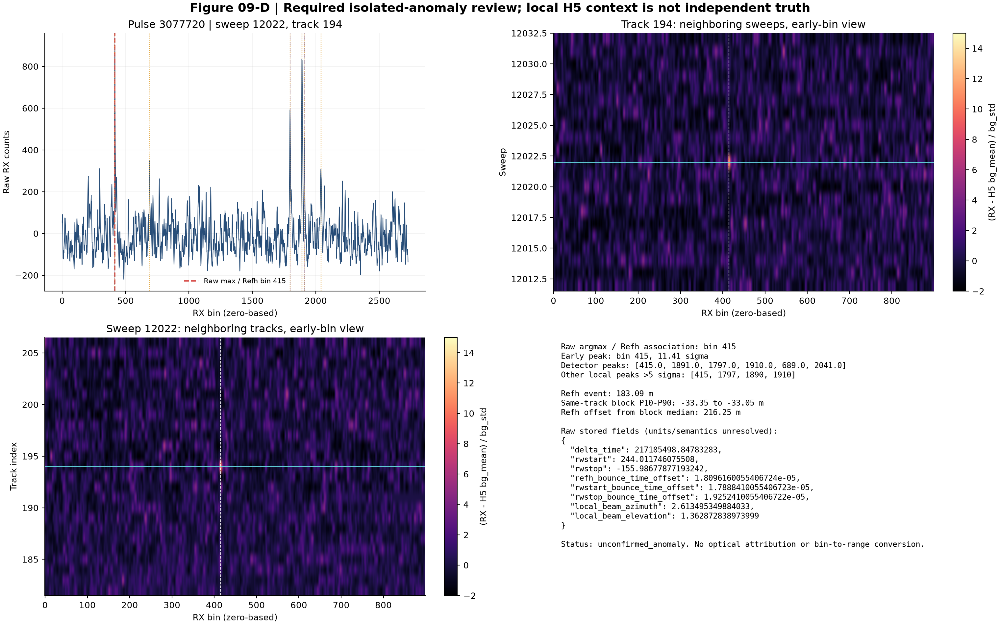

2681

In [7]:
from scipy.signal import find_peaks, peak_widths

event_sweep = int(index.sweep_num[EVENT_PULSE]); event_track = int(index.track_num[EVENT_PULSE])
if int(index.record_index_grid[event_sweep,event_track]) != EVENT_PULSE:
    raise RuntimeError("Event pulse identity does not match the verified sweep/track grid.")
if (event_sweep, event_track) != (12022, 194):
    raise RuntimeError("The stored pulse 3077720 sweep/track identity changed.")
if event_sweep < START_SWEEP or event_sweep >= STOP_SWEEP:
    raise RuntimeError("The required event pulse is outside the retained 90-sweep baseline.")
event_offset = event_sweep - START_SWEEP
event_track_offset = event_track
event_wave = rx_block[event_offset,event_track_offset].astype(float)
event_bg = float(scalar["bg_mean"][event_offset,event_track_offset]); event_noise = float(scalar["bg_std"][event_offset,event_track_offset])
event_z = (event_wave-event_bg)/max(event_noise,1e-6)
event_raw_argmax = int(np.argmax(event_wave)); event_early_bin = int(np.argmax(event_z[:EARLY_BINS]))
if event_raw_argmax != 415:
    raise RuntimeError("The stored pulse 3077720 raw maximum bin changed from its audited baseline.")
zpeaks, zprops = find_peaks(event_z,height=5.0,prominence=4.0,distance=5)
peak_width = peak_widths(event_z,zpeaks,rel_height=0.5)[0] if len(zpeaks) else np.array([])
event_peak_rows = [{"bin":int(b),"excess_sigma":float(event_z[b]),"prominence_sigma":float(zprops["prominences"][i]),"width_bins":float(peak_width[i])} for i,b in enumerate(zpeaks)]
event_h5_values = {}
with h5py.File(H5_PATH,"r") as h5:
    for name in ["delta_time","rwstart","rwstop","refh_bounce_time_offset","rwstart_bounce_time_offset","rwstop_bounce_time_offset","local_beam_azimuth","local_beam_elevation"]:
        if name in h5: event_h5_values[name] = float(h5[name][EVENT_PULSE])
    event_root_attrs = {k:str(v) for k,v in h5.attrs.items()}
local_refh = scalar["refh"][:,event_track]
event_refh_summary = {"event_refh_m":float(scalar["refh"][event_offset,event_track]),"same_track_median_m":float(np.nanmedian(local_refh)),"same_track_p10_m":float(np.nanpercentile(local_refh,10)),"same_track_p90_m":float(np.nanpercentile(local_refh,90)),"event_minus_median_m":float(scalar["refh"][event_offset,event_track]-np.nanmedian(local_refh))}
deep_detector_config = json.loads((ROOT/"outputs/notebooks/06_waveform_gallery/method_improvement"/H5_PATH.stem/"selected_waveform_cases.json").read_text(encoding="utf-8"))["detector_config"] if (ROOT/"outputs/notebooks/06_waveform_gallery/method_improvement"/H5_PATH.stem/"selected_waveform_cases.json").is_file() else build_detector_config(default_config([H5_PATH],OUTPUT_DIR))
event_detector = detect_candidate_components_1d(event_wave,event_bg,event_noise,float(scalar["refh_thres"][event_offset,event_track]),deep_detector_config)
print({"pulse_index":EVENT_PULSE,"sweep_num":event_sweep,"track_num":event_track,"early_peak_bin":event_early_bin,"early_peak_sigma":float(event_z[event_early_bin]),"raw_argmax_bin":event_raw_argmax,"detector_peaks":[{"peak_bin":float(x["peak_bin"]),"prominence_sigma":float(x.get("prominence_sigma",np.nan))} for x in event_detector],"local_high_peaks":event_peak_rows,"stored_H5_values_no_bin_conversion":event_h5_values,"same_track_Refh_context":event_refh_summary})

local_sweeps = np.arange(max(START_SWEEP,event_sweep-10),min(STOP_SWEEP,event_sweep+11))
local_offsets = local_sweeps-START_SWEEP
near_tracks = np.arange(max(0,event_track-12),min(index.n_tracks,event_track+13))
fig, axes = plt.subplots(2,2,figsize=(16,10),constrained_layout=True)
xbin=np.arange(event_wave.size)
axes[0,0].plot(xbin,event_wave,color="#274d78",lw=.8)
axes[0,0].axvline(event_raw_argmax,color="#d9534f",ls="--",label=f"Raw max / Refh bin {event_raw_argmax}")
for item in event_detector: axes[0,0].axvline(float(item["peak_bin"]),color="#e4a83e",ls=":",lw=.9)
for item in event_peak_rows: axes[0,0].axvline(item["bin"],color="#7d5a91",ls="-.",lw=.65,alpha=.6)
axes[0,0].set(xlabel="RX bin (zero-based)",ylabel="Raw RX counts",title=f"Pulse {EVENT_PULSE} | sweep {event_sweep}, track {event_track}")
axes[0,0].legend(frameon=False,fontsize=8); axes[0,0].grid(alpha=.15)
track_z=(rx_block[local_offsets,event_track,:]-scalar["bg_mean"][local_offsets,event_track,None])/np.maximum(scalar["bg_std"][local_offsets,event_track,None],1e-6)
im=axes[0,1].imshow(np.clip(track_z[:,:900],-2,15),origin="lower",aspect="auto",extent=[-.5,899,local_sweeps[0]-.5,local_sweeps[-1]+.5],cmap="magma",vmin=-2,vmax=15)
axes[0,1].axhline(event_sweep,color="#63d6df",lw=1); axes[0,1].axvline(event_early_bin,color="white",ls="--",lw=.8)
axes[0,1].set(xlabel="RX bin (zero-based)",ylabel="Sweep",title=f"Track {event_track}: neighboring sweeps, early-bin view")
fig.colorbar(im,ax=axes[0,1],label="(RX - H5 bg_mean) / bg_std")
track_ix=near_tracks
same_z=(rx_block[event_offset,track_ix,:900]-scalar["bg_mean"][event_offset,track_ix,None])/np.maximum(scalar["bg_std"][event_offset,track_ix,None],1e-6)
im2=axes[1,0].imshow(np.clip(same_z,-2,15),origin="lower",aspect="auto",extent=[-.5,899,near_tracks[0]-.5,near_tracks[-1]+.5],cmap="magma",vmin=-2,vmax=15)
axes[1,0].axhline(event_track,color="#63d6df",lw=1); axes[1,0].axvline(event_early_bin,color="white",ls="--",lw=.8)
axes[1,0].set(xlabel="RX bin (zero-based)",ylabel="Track index",title=f"Sweep {event_sweep}: neighboring tracks, early-bin view")
fig.colorbar(im2,ax=axes[1,0],label="(RX - H5 bg_mean) / bg_std")
axes[1,1].axis("off")
diagnostic_lines = [
    f"Raw argmax / Refh association: bin {event_raw_argmax}",
    f"Early peak: bin {event_early_bin}, {event_z[event_early_bin]:.2f} sigma",
    f"Detector peaks: {[round(float(x['peak_bin']),1) for x in event_detector]}",
    f"Other local peaks >5 sigma: {[x['bin'] for x in event_peak_rows]}",
    "",
    f"Refh event: {event_refh_summary['event_refh_m']:.2f} m",
    f"Same-track block P10-P90: {event_refh_summary['same_track_p10_m']:.2f} to {event_refh_summary['same_track_p90_m']:.2f} m",
    f"Refh offset from block median: {event_refh_summary['event_minus_median_m']:.2f} m",
    "",
    "Raw stored fields (units/semantics unresolved):",
    json.dumps(event_h5_values, indent=2),
    "",
    "Status: unconfirmed_anomaly. No optical attribution or bin-to-range conversion.",
]
axes[1,1].text(.02,.98,chr(10).join(diagnostic_lines),va="top",fontsize=9,family="monospace")
fig.suptitle("Figure 09-D | Required isolated-anomaly review; local H5 context is not independent truth",fontsize=14,weight="bold")
fig.savefig(OUTPUT_DIR/"event_3077720_diagnostic.png",dpi=DPI)
plt.close(fig)
display(Image(filename=str(OUTPUT_DIR/"event_3077720_diagnostic.png")))
event_diagnostic={"pulse_index":EVENT_PULSE,"sweep_num":event_sweep,"track_num":event_track,"early_peak_bin":event_early_bin,"early_peak_sigma":float(event_z[event_early_bin]),"raw_argmax_bin":event_raw_argmax,"official_refh_associated_bin":event_raw_argmax,"detector_peaks":[{"peak_bin":float(item["peak_bin"]),"prominence_sigma":float(item.get("prominence_sigma",np.nan))} for item in event_detector],"other_local_peaks_over_5sigma":event_peak_rows,"stored_H5_values_without_unit_claim":event_h5_values,"root_time_constants_and_epoch":{k:v for k,v in event_root_attrs.items() if any(t in k.lower() for t in ["epoch","ns_to","sec_to","speed_of_light"])},"same_track_Refh_context":event_refh_summary,"independent_scene_truth":False,"status":"unconfirmed_anomaly","interpretation":"The isolated event and its local Refh offset do not distinguish scene signal, direct optical reflection, receiver transient, delayed ghost, or another cause."}
(OUTPUT_DIR/"event_3077720_diagnostic.json").write_text(json.dumps(event_diagnostic,indent=2,allow_nan=False),encoding="utf-8")


## Figure 09-A | Single-sweep RX heatmaps

The paired maps show the configured anchor sweep (currently 12039): one RX waveform for each of 256 tracks across all 2,728 bins. The first map shows RX counts after subtracting that pulse's H5 `bg_mean`. The second shows `(RX - bg_mean) / bg_std` in units of background standard deviation. This per-bin standardized amplitude is SNR-like, not the H5 `refh_snr` field. Color limits saturate at the 99.8th percentile of absolute values for legibility; the underlying samples are retained.

## Multi-sweep screening overview

The overview below summarizes early-bin occupancy and isolated per-pulse transients across the selected block. Red outlines appear only for bands that pass the stated gates; an empty outline layer is a valid diagnostic outcome.

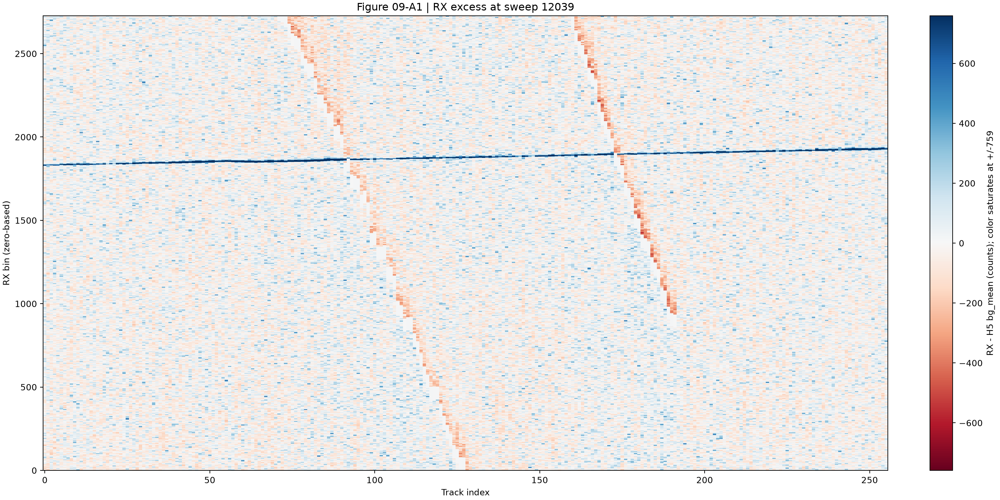

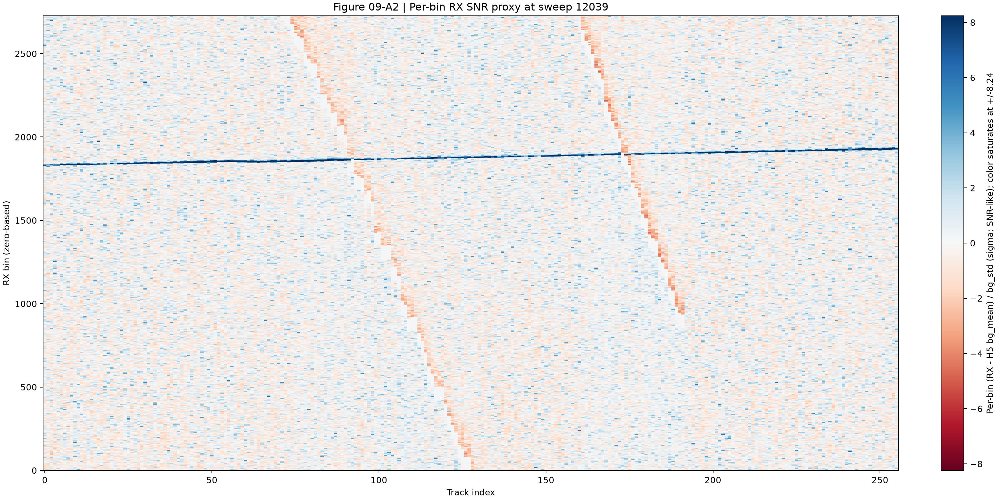

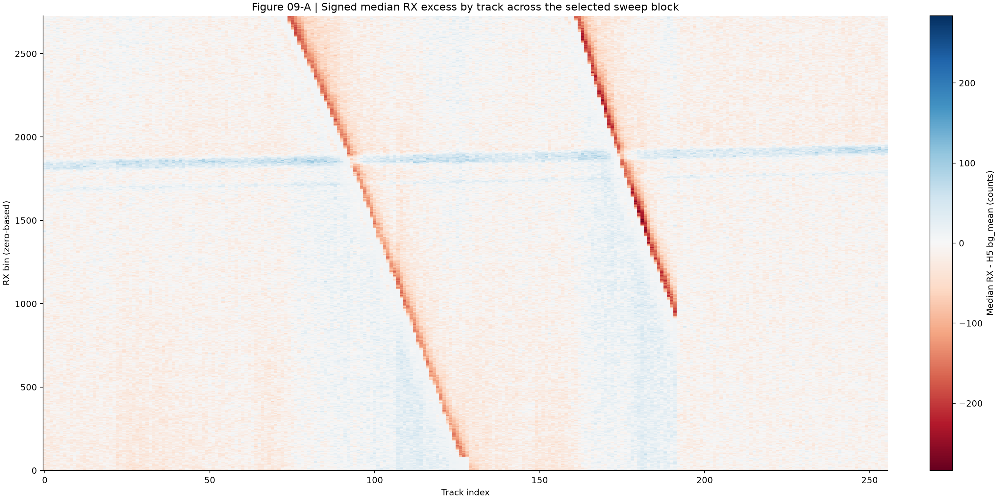

In [8]:
single_sweep_offset = ANCHOR_SWEEP - START_SWEEP
if not 0 <= single_sweep_offset < len(rx_block):
    raise ValueError("ANCHOR_SWEEP is outside the loaded sweep block.")
single_sweep_rx = rx_block[single_sweep_offset].astype(np.float32)
single_sweep_bg = scalar["bg_mean"][single_sweep_offset].astype(np.float32)
single_sweep_std = scalar["bg_std"][single_sweep_offset].astype(np.float32)
single_sweep_excess = single_sweep_rx - single_sweep_bg[:, None]
single_sweep_sigma = np.divide(
    single_sweep_excess,
    single_sweep_std[:, None],
    out=np.full_like(single_sweep_excess, np.nan),
    where=np.isfinite(single_sweep_std[:, None]) & (single_sweep_std[:, None] > 0),
)
for values, title, colorbar_label, filename in [
    (single_sweep_excess, f"Figure 09-A1 | RX excess at sweep {ANCHOR_SWEEP}",
     "RX - H5 bg_mean (counts)", "range_track_heatmap.png"),
    (single_sweep_sigma, f"Figure 09-A2 | Per-bin RX SNR proxy at sweep {ANCHOR_SWEEP}",
     "Per-bin (RX - H5 bg_mean) / bg_std (sigma; SNR-like)", "range_track_sigma_heatmap.png"),
]:
    finite_abs = np.abs(values[np.isfinite(values)])
    vmax = float(np.nanpercentile(finite_abs, 99.8)) if finite_abs.size else 1.0
    vmax = max(vmax, 1e-6)
    fig, ax = plt.subplots(figsize=(16, 8), constrained_layout=True)
    im = ax.imshow(values.T, origin="lower", aspect="auto",
                   extent=[-0.5, index.n_tracks - 0.5, -0.5, rx_block.shape[2] - 0.5],
                   cmap="RdBu", vmin=-vmax, vmax=vmax, interpolation="nearest")
    ax.set(xlabel="Track index", ylabel="RX bin (zero-based)", title=title)
    fig.colorbar(im, ax=ax, label=f"{colorbar_label}; color saturates at +/-{vmax:.3g}")
    figure_path = OUTPUT_DIR / filename
    fig.savefig(figure_path, dpi=DPI)
    plt.close(fig)
    display(Image(filename=str(figure_path)))

occ_grid = scores.pivot(index="bin", columns="track_num", values="occupancy").to_numpy()
score_grid = scores.pivot(index="bin", columns="track_num", values="ghost_score").to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
occ_vmax = max(0.05, float(np.nanpercentile(occ_grid, 99.8)))
im0 = axes[0, 0].imshow(occ_grid, origin="lower", aspect="auto", extent=[-0.5, index.n_tracks - 0.5, -0.5, EARLY_BINS - 0.5],
                         cmap="magma", vmin=0, vmax=occ_vmax, interpolation="nearest")
axes[0, 0].set(title=f"Early-bin occupancy: excess > {THRESHOLD_SIGMA:g} sigma", xlabel="Track", ylabel="RX bin")
fig.colorbar(im0, ax=axes[0, 0], label="Fraction of sweeps")
im1 = axes[0, 1].imshow(score_grid, origin="lower", aspect="auto", extent=[-0.5, index.n_tracks - 0.5, -0.5, EARLY_BINS - 0.5],
                         cmap="cividis", vmin=0, vmax=1, interpolation="nearest")
axes[0, 1].set(title="Interpretable screening score (0 to 1)", xlabel="Track", ylabel="RX bin")
fig.colorbar(im1, ax=axes[0, 1], label="Score")
axes[1, 0].hist(early_peak_z.ravel(), bins=np.arange(0, max(13, int(np.nanmax(early_peak_z)) + 2), 0.5), color="#577a9e")
axes[1, 0].axvline(8, color="#d9534f", ls="--", label="8 sigma review level")
axes[1, 0].set(title="Strongest early-bin value per pulse", xlabel="Maximum early-bin excess (sigma)", ylabel="Pulse count")
axes[1, 0].legend(frameon=False)
axes[1, 1].axis("off")
axes[1, 1].text(0.02, 0.95,
    f"Selected block: sweeps {START_SWEEP} to {STOP_SWEEP-1}; {index.n_tracks} tracks\n"
    f"Early gate: bins 0 to {EARLY_BINS-1}; H5 bg_mean/bg_std\n"
    f"Candidate bands passing all gates: {len(candidate_bands)}\n"
    f"Largest fixed-bin occupancy: {scores.occupancy.max():.1%}\n"
    f"Pulses with any early sample >8sigma: {(early_peak_z > 8).sum()} / {early_peak_z.size}\n\n"
    + ("No recurring band was identified in this selected block.\nThe highest isolated transient is not a confirmed ghost."
       if candidate_bands.empty else "Bands require human review; a fixed-bin band does not prove an optical reflection."),
    va="top", fontsize=12, linespacing=1.6)
fig.suptitle("Window-reflection hypothesis | recurrence, amplitude and scene proxy", fontsize=16, fontweight="bold")
fig.savefig(OUTPUT_DIR / "window_reflection_overview.png", dpi=DPI)
plt.close(fig)
display(Image(filename=str(OUTPUT_DIR / "window_reflection_overview.png")))

## Figure 09-A3 | All-sweep median RX excess heatmap

For each track and RX bin, this map shows the exact median across all 14,080 sweeps of that pulse's `RX - H5 bg_mean` value (counts). The sweep/track-to-pulse mapping comes from `build_record_index_grid`. The RX data are streamed in HDF5-sized blocks into a temporary disk-backed array, then reduced one track at a time; the temporary array is removed when the cell finishes. Color limits saturate symmetrically at the 99.8th percentile of absolute median values.


{'sweeps': 14080, 'tracks': 256, 'rx_bins': 2728, 'definition': 'median_sweep(rx_waveform[pulse] - bg_mean[pulse])', 'color_limit_counts': 127.12867736816406, 'elapsed_seconds': 431.3, 'figure': 'outputs\\notebooks\\09_nadir_window_reflection\\method_improvement\\casals_l1b_20241118T171757_001_02\\range_track_all_sweeps_median_heatmap.png'}


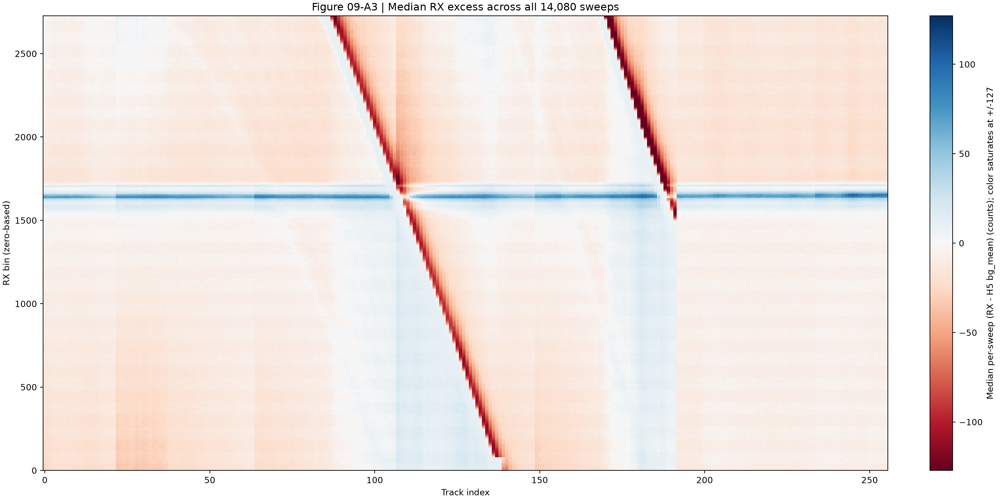

In [12]:
from tempfile import TemporaryDirectory
import gc
import time
from casals_l1b.waveform import build_record_index_grid

all_sweep_started = time.perf_counter()
with h5py.File(H5_PATH, "r") as h5:
    all_sweep_index = build_record_index_grid(h5)
    if not all_sweep_index.complete_rectangular_grid or all_sweep_index.duplicate_sweep_track_cells:
        raise RuntimeError("The full-granule sweep/track grid is not a unique complete rectangle.")

    rx_ds = h5["rx_waveform"]
    if rx_ds.ndim != 2 or rx_ds.shape[0] != all_sweep_index.n_records:
        raise RuntimeError(f"Expected RX records on axis 0, got shape {rx_ds.shape}.")
    all_n_sweeps = all_sweep_index.n_sweeps
    all_n_tracks = all_sweep_index.n_tracks
    all_n_bins = int(rx_ds.shape[1])
    chunk_records = int(rx_ds.chunks[0]) if rx_ds.chunks else 14080
    if chunk_records % all_n_tracks:
        raise RuntimeError("The RX storage chunk does not contain a whole number of sweeps.")
    bg_mean_by_record = np.asarray(h5["bg_mean"][...], dtype=np.float32)
    if not np.all(np.isfinite(bg_mean_by_record)):
        raise RuntimeError("H5 bg_mean contains non-finite values; median handling needs review.")

    with TemporaryDirectory(prefix="casals_all_sweep_median_") as scratch_dir:
        raw_by_track = np.memmap(
            Path(scratch_dir) / "rx_by_track_int16.bin", mode="w+", dtype=np.int16,
            shape=(all_n_tracks, all_n_sweeps, all_n_bins),
        )
        for block_number, record_start in enumerate(range(0, all_sweep_index.n_records, chunk_records), start=1):
            record_stop = min(record_start + chunk_records, all_sweep_index.n_records)
            sweep_ids = all_sweep_index.sweep_num[record_start:record_stop]
            track_ids = all_sweep_index.track_num[record_start:record_stop]
            unique_sweeps = np.unique(sweep_ids)
            sweep_start = int(unique_sweeps[0])
            sweep_stop = int(unique_sweeps[-1]) + 1
            if (unique_sweeps.size != (record_stop - record_start) // all_n_tracks
                    or not np.array_equal(unique_sweeps, np.arange(sweep_start, sweep_stop))):
                raise RuntimeError(f"RX storage block {block_number} does not align to complete sweeps.")
            counts_per_track = np.bincount(track_ids, minlength=all_n_tracks)
            if not np.array_equal(counts_per_track, np.full(all_n_tracks, unique_sweeps.size)):
                raise RuntimeError(f"RX storage block {block_number} does not contain each track once per sweep.")

            raw_block = np.asarray(rx_ds[record_start:record_stop, :], dtype=np.int16)
            organized_block = np.empty((unique_sweeps.size, all_n_tracks, all_n_bins), dtype=np.int16)
            organized_block[sweep_ids - sweep_start, track_ids, :] = raw_block
            for track_id in range(all_n_tracks):
                raw_by_track[track_id, sweep_start:sweep_stop, :] = organized_block[:, track_id, :]
            if block_number % 16 == 0 or record_stop == all_sweep_index.n_records:
                print(f"Streamed {sweep_stop:,} / {all_n_sweeps:,} sweeps", flush=True)
            del raw_block, organized_block

        raw_by_track.flush()
        all_sweep_median_excess = np.empty((all_n_tracks, all_n_bins), dtype=np.float32)
        for track_id in range(all_n_tracks):
            record_ids = all_sweep_index.record_index_grid[:, track_id]
            residuals = np.asarray(raw_by_track[track_id, :, :], dtype=np.float32)
            residuals -= bg_mean_by_record[record_ids, None]
            all_sweep_median_excess[track_id, :] = np.median(residuals, axis=0, overwrite_input=True)
            if (track_id + 1) % 64 == 0:
                print(f"Computed exact medians for {track_id + 1:,} / {all_n_tracks:,} tracks", flush=True)
        del raw_by_track
        gc.collect()

finite_abs = np.abs(all_sweep_median_excess[np.isfinite(all_sweep_median_excess)])
if finite_abs.size == 0:
    raise RuntimeError("The all-sweep median residual map has no finite values.")
all_sweep_vmax = max(float(np.percentile(finite_abs, 99.8)), 1e-6)
fig, ax = plt.subplots(figsize=(16, 8), constrained_layout=True)
im = ax.imshow(
    all_sweep_median_excess.T, origin="lower", aspect="auto",
    extent=[-0.5, all_n_tracks - 0.5, -0.5, all_n_bins - 0.5],
    cmap="RdBu", vmin=-all_sweep_vmax, vmax=all_sweep_vmax, interpolation="nearest",
)
ax.set(
    xlabel="Track index", ylabel="RX bin (zero-based)",
    title=f"Figure 09-A3 | Median RX excess across all {all_n_sweeps:,} sweeps",
)
fig.colorbar(
    im, ax=ax,
    label=f"Median per-sweep (RX - H5 bg_mean) (counts); color saturates at +/-{all_sweep_vmax:.3g}",
)
all_sweep_median_path = OUTPUT_DIR / "range_track_all_sweeps_median_heatmap.png"
fig.savefig(all_sweep_median_path, dpi=DPI)
plt.close(fig)
print({
    "sweeps": int(all_n_sweeps), "tracks": int(all_n_tracks), "rx_bins": int(all_n_bins),
    "definition": "median_sweep(rx_waveform[pulse] - bg_mean[pulse])",
    "color_limit_counts": float(all_sweep_vmax),
    "elapsed_seconds": round(time.perf_counter() - all_sweep_started, 1),
    "figure": str(all_sweep_median_path.relative_to(ROOT)),
})
display(Image(filename=str(all_sweep_median_path)))


## Figure 09-B | Track context and local waveform comparisons

Figure 09-B2 is one large heatmap with a single plotting area. It stacks the screening-event track and two same-sweep local comparison tracks, each across the same symmetric 180-sweep context. The x axis shows early RX bins; each row shows signed `RX - H5 bg_mean` counts for one sweep. Dashed bounds mark the original 90-sweep screen, and the selected sweep and event bin are marked for reference. These are local comparisons, not instrument truth.

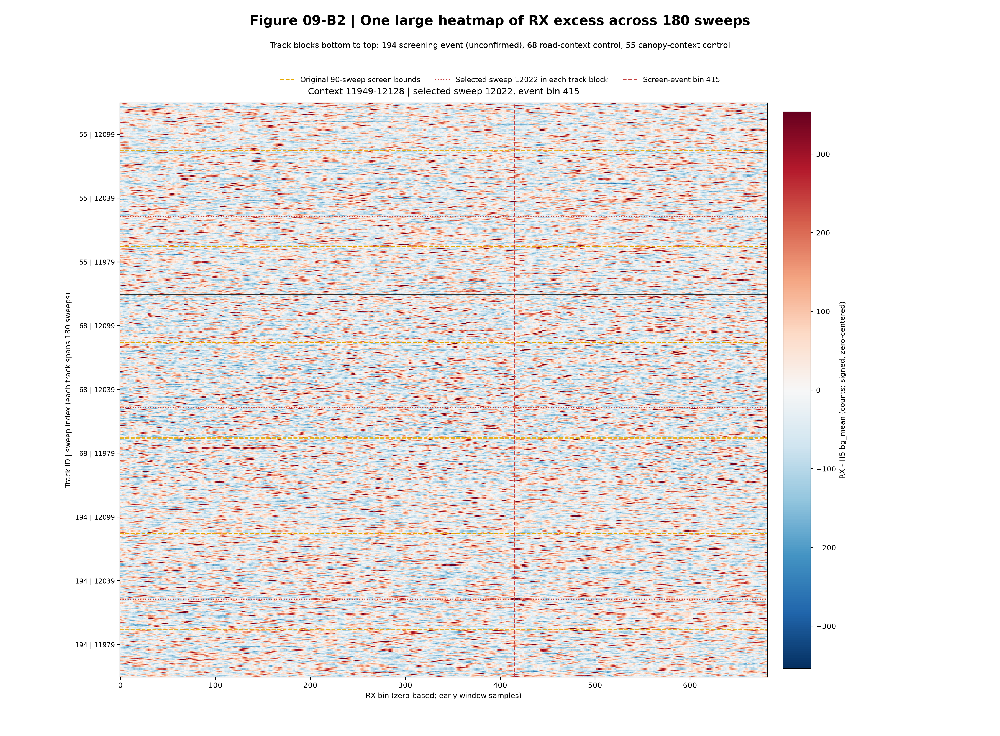

In [9]:
screen_track = int(screen["track_num"])
tracks_to_show = list(dict.fromkeys([screen_track, 68, 55] + candidate_bands.track_num.astype(int).tolist()))[:4]
# Keep the original 90-sweep screening baseline and add a symmetric 180-sweep sensitivity block.
context_margin = (STOP_SWEEP - START_SWEEP) // 2
context_start = max(0, START_SWEEP - context_margin)
context_stop = min(index.n_sweeps, STOP_SWEEP + context_margin)
if context_stop - context_start != 2 * (STOP_SWEEP - START_SWEEP):
    raise RuntimeError("Could not form the doubled 180-sweep context block.")
with h5py.File(H5_PATH, "r") as h5:
    context_rx_block, context_index, context_record_ids = read_sweep_block(
        h5, "rx_waveform", context_start, context_stop
    )
    if not context_index.complete_rectangular_grid or context_index.duplicate_sweep_track_cells:
        raise RuntimeError("The extended sweep/track grid is not a unique complete rectangle.")
    context_scalar = {
        name: read_scalar_block(h5, name, context_record_ids)
        for name in ("bg_mean", "bg_std", "refh")
    }
context_scores = score_track_bins(
    context_rx_block, context_scalar["bg_mean"], context_scalar["bg_std"], context_scalar["refh"],
    early_bins=EARLY_BINS, threshold_sigma=THRESHOLD_SIGMA,
)
context_candidate_bands = extract_candidate_bands(
    context_scores, occupancy_min=OCCUPANCY_MIN,
    median_excess_sigma_min=EXCESS_SIGMA_MIN, score_min=SCORE_MIN,
)
screen_bin = int(screen["early_peak_bin"])
screen_context_row = context_scores.loc[
    (context_scores.track_num == screen_track) & (context_scores.bin == screen_bin)
].iloc[0]
context_summary = {
    "status": "supplemental 180-sweep sensitivity; original 90-sweep baseline preserved",
    "sweep_start_inclusive": context_start,
    "sweep_stop_exclusive": context_stop,
    "n_sweeps": context_stop - context_start,
    "n_tracks": int(context_rx_block.shape[1]),
    "n_pulses": int(context_record_ids.size),
    "early_bins": EARLY_BINS,
    "candidate_band_count": int(len(context_candidate_bands)),
    "max_fixed_bin_occupancy": float(context_scores.occupancy.max()),
    "screen_event_bin": {
        "track": screen_track,
        "bin": screen_bin,
        "threshold_event_count": int(screen_context_row.event_count),
        "valid_sweeps": int(screen_context_row.valid_sweep_count),
        "occupancy": float(screen_context_row.occupancy),
        "median_excess_sigma": float(screen_context_row.median_excess_sigma),
    },
}
context_scores.to_csv(OUTPUT_DIR / "extended_180_sweep_track_bin_scores.csv", index=False)
context_candidate_bands.to_csv(OUTPUT_DIR / "extended_180_sweep_candidate_bands.csv", index=False)
(OUTPUT_DIR / "extended_180_sweep_summary.json").write_text(
    json.dumps(context_summary, indent=2), encoding="utf-8"
)
print("Supplemental doubled-range sensitivity:")
display(pd.DataFrame([context_summary]))

# One large heatmap keeps the full 180-sweep comparison in a single plot.
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

screen_track = int(screen["track_num"])
sample_sweep = int(screen["sweep_num"])
plot_tracks = [screen_track, 68, 55]
early_wave_stop = min(context_rx_block.shape[2], EARLY_BINS + 81)
if context_stop - context_start != 180:
    raise RuntimeError("Expected the doubled 180-sweep context block.")
if any(track < 0 or track >= context_rx_block.shape[1] for track in plot_tracks):
    raise RuntimeError("A requested local-comparison track is outside the H5 grid.")

block_sweeps = context_stop - context_start
track_excess_blocks = [
    context_rx_block[:, track, :early_wave_stop].astype(np.float32)
    - context_scalar["bg_mean"][:, track, None].astype(np.float32)
    for track in plot_tracks
]
stacked_excess = np.concatenate(track_excess_blocks, axis=0)
finite_excess = np.abs(stacked_excess[np.isfinite(stacked_excess)])
if finite_excess.size == 0:
    raise RuntimeError("The selected 180-sweep waveform blocks have no finite samples.")
color_limit = max(float(np.percentile(finite_excess, 99.7)), 1.0)

fig, ax = plt.subplots(figsize=(19, 14), constrained_layout=False)
image = ax.imshow(
    stacked_excess, origin="lower", aspect="auto",
    extent=[-0.5, early_wave_stop - 0.5, -0.5, stacked_excess.shape[0] - 0.5],
    cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-color_limit, vcenter=0.0, vmax=color_limit),
    interpolation="nearest",
)
for group_index, track in enumerate(plot_tracks):
    base = group_index * block_sweeps
    ax.axhline(base - 0.5, color="#303030", lw=1.0)
    ax.axhline(base + block_sweeps - 0.5, color="#303030", lw=1.0)
    for boundary in (START_SWEEP, STOP_SWEEP):
        ax.axhline(base + (boundary - context_start) - 0.5, color="#e7a900", ls="--", lw=1.4)
    ax.axhline(base + sample_sweep - context_start, color="#c33d3d", ls=":", lw=1.3)
ax.axvline(int(screen["early_peak_bin"]), color="#c33d3d", ls="--", lw=1.4)

label_offsets = np.array([30, 90, 150], dtype=int)
yticks, ylabels = [], []
for group_index, track in enumerate(plot_tracks):
    for offset in label_offsets:
        yticks.append(group_index * block_sweeps + int(offset))
        ylabels.append(f"{track} | {context_start + int(offset)}")
ax.set_yticks(yticks, ylabels)
ax.set(
    xlim=(-0.5, early_wave_stop - 0.5), ylim=(-0.5, stacked_excess.shape[0] - 0.5),
    xlabel="RX bin (zero-based; early-window samples)",
    ylabel="Track ID | sweep index (each track spans 180 sweeps)",
)
ax.tick_params(axis="y", labelsize=9)
ax.set_title(
    f"Context {context_start}-{context_stop - 1} | selected sweep {sample_sweep}, event bin {int(screen['early_peak_bin'])}",
    fontsize=12, pad=12,
)
fig.suptitle("Figure 09-B2 | One large heatmap of RX excess across 180 sweeps", fontsize=18, fontweight="bold", y=0.98)
fig.text(
    0.5, 0.935,
    f"Track blocks bottom to top: {screen_track} screening event (unconfirmed), 68 road-context control, 55 canopy-context control",
    ha="center", fontsize=11,
)
legend_items = [
    Line2D([0], [0], color="#e7a900", ls="--", lw=1.5, label="Original 90-sweep screen bounds"),
    Line2D([0], [0], color="#c33d3d", ls=":", lw=1.4, label=f"Selected sweep {sample_sweep} in each track block"),
    Line2D([0], [0], color="#c33d3d", ls="--", lw=1.4, label=f"Screen-event bin {int(screen['early_peak_bin'])}"),
]
fig.legend(legend_items, [item.get_label() for item in legend_items], loc="upper center", bbox_to_anchor=(0.5, 0.905), ncol=3, frameon=False, fontsize=10)
fig.subplots_adjust(left=0.12, right=0.90, top=0.86, bottom=0.08)
fig.colorbar(image, ax=ax, label="RX - H5 bg_mean (counts; signed, zero-centered)", shrink=0.97, pad=0.02)
single_figure_path = OUTPUT_DIR / "track_sweep_context_180.png"
fig.savefig(single_figure_path, dpi=DPI)
plt.close(fig)
display(Image(filename=str(single_figure_path)))
del context_rx_block, context_scalar, context_index, context_record_ids


## Mitigation comparison on the real baseline event

When a supported interval is absent, **no supported mitigation is applied**: flagging returns no bins, masking is a no-op, and template subtraction is skipped. The real RX array is retained unchanged. If independent evidence supports a future interval, flag-only plus downstream review is the conservative first option; masking and template subtraction require separate validation.


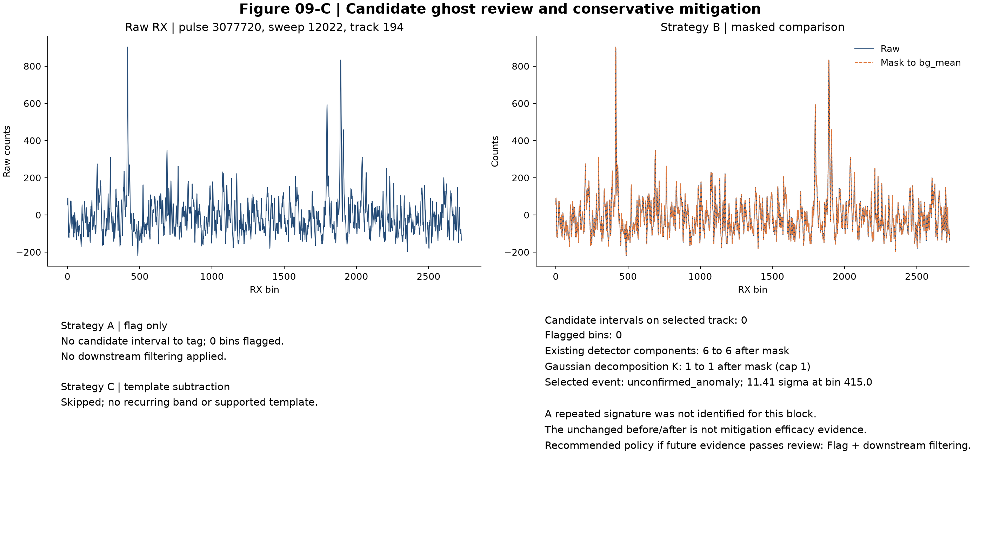

{'pulse_index': 3077720, 'sweep_num': 12022, 'track_num': 194, 'early_peak_bin': 415, 'early_peak_sigma': 11.407564375792198, 'candidate_intervals': [], 'flagged_bins': 0, 'fit_component_cap': 1, 'detector_components_before': 6, 'detector_components_after_mask': 6, 'detector_components_after_template': None, 'decomposition_k_before': 1, 'decomposition_k_after_mask': 1, 'template_applied': False, 'interpretation': 'No correction or mitigation was applied because no candidate band was supported.'}


In [10]:
pulse = int(screen["pulse_index"])
sweep = int(screen["sweep_num"])
track = int(screen["track_num"])
sweep_offset = sweep - START_SWEEP
track_offset = track
wave = rx_block[sweep_offset, track_offset].astype(float)
bg_mean = float(scalar["bg_mean"][sweep_offset, track_offset])
bg_std = float(scalar["bg_std"][sweep_offset, track_offset])
refh_thres = float(scalar["refh_thres"][sweep_offset, track_offset])
track_bands = candidate_bands[candidate_bands.track_num == track]
intervals = [{"start_bin": int(row.start_bin), "end_bin": int(row.end_bin)} for row in track_bands.itertuples()]
flags = flag_bins(wave.size, intervals)
masked = mask_bins(wave, intervals)
masked_for_analysis = wave.copy() if not intervals else np.where(np.isfinite(masked), masked, bg_mean)
if candidate_bands.empty:
    assert intervals == [] and int(flags.sum()) == 0
    np.testing.assert_array_equal(masked, wave)
    assert np.array_equal(masked_for_analysis, wave, equal_nan=True)

template = None
subtracted = None
if intervals:
    template = np.zeros(wave.size, dtype=float)
    for interval in intervals:
        lo, hi = interval["start_bin"], interval["end_bin"]
        local = rx_block[:, track, lo : hi + 1] - scalar["bg_mean"][:, track, None]
        template[lo : hi + 1] = np.nanmedian(local, axis=0)
    subtracted = bg_mean + subtract_template(wave - bg_mean, template)
if candidate_bands.empty:
    assert template is None and subtracted is None

config_path = ROOT / "outputs/notebooks/06_waveform_gallery/method_improvement" / H5_PATH.stem / "selected_waveform_cases.json"
if config_path.is_file():
    detector_config = json.loads(config_path.read_text(encoding="utf-8"))["detector_config"]
    detector_config_source = str(config_path.relative_to(ROOT))
else:
    detector_config = build_detector_config(default_config([H5_PATH], OUTPUT_DIR))
    detector_config_source = "current package default detector configuration"

def detect(y):
    return detect_candidate_components_1d(y, bg_mean, bg_std, refh_thres, detector_config)

components_before = detect(wave)
components_masked = detect(masked_for_analysis)
components_subtracted = detect(subtracted) if subtracted is not None else None
baseline_info = estimate_baseline(wave, bg_mean, bg_std)
fit_component_cap = 5 if float(scalar["refh_snr"][sweep_offset, track_offset]) >= 5.0 else 1
fit_before = fit_gaussian_components(wave, baseline_info["baseline"], baseline_info["noise_sigma"],
                                     components_before, max_components=fit_component_cap)
fit_masked = fit_gaussian_components(masked_for_analysis, baseline_info["baseline"], baseline_info["noise_sigma"],
                                     components_masked, max_components=fit_component_cap)

fig, axes = plt.subplots(2, 2, figsize=(15, 8), constrained_layout=True)
bins = np.arange(wave.size)
axes[0, 0].plot(bins, wave, color="#274d78", lw=0.8)
for item in intervals:
    axes[0, 0].axvspan(item["start_bin"], item["end_bin"], color="#e94f37", alpha=0.2)
axes[0, 0].set(title=f"Raw RX | pulse {pulse}, sweep {sweep}, track {track}", xlabel="RX bin", ylabel="Raw counts")
axes[0, 1].plot(bins, wave, color="#274d78", lw=0.8, label="Raw")
axes[0, 1].plot(bins, masked_for_analysis, color="#e17c42", lw=0.9, ls="--", label="Mask to bg_mean")
axes[0, 1].set(title="Strategy B | masked comparison", xlabel="RX bin", ylabel="Counts")
axes[0, 1].legend(frameon=False)
if subtracted is None:
    axes[1, 0].axis("off")
    axes[1, 0].text(0.03, 0.92, "Strategy A | flag only\nNo candidate interval to tag; 0 bins flagged.\nNo downstream filtering applied.\n\nStrategy C | template subtraction\nSkipped; no recurring band or supported template.", va="top", fontsize=11, linespacing=1.5)
else:
    axes[1, 0].plot(bins, wave, color="#274d78", lw=0.8, label="Raw")
    axes[1, 0].plot(bins, subtracted, color="#a34b6b", lw=0.8, label="Exploratory template-subtracted")
    axes[1, 0].set(title="Strategy C | exploratory only", xlabel="RX bin", ylabel="Counts")
    axes[1, 0].legend(frameon=False)
axes[1, 1].axis("off")
axes[1, 1].text(0.02, 0.95,
    f"Candidate intervals on selected track: {len(intervals)}\n"
    f"Flagged bins: {int(flags.sum())}\n"
    f"Existing detector components: {len(components_before)} to {len(components_masked)} after mask\n"
    f"Gaussian decomposition K: {fit_before['chosen_k']} to {fit_masked['chosen_k']} after mask (cap {fit_component_cap})\n"
    f"Selected event: {screen_status}; {screen['early_peak_sigma']:.2f} sigma at bin {screen['early_peak_bin']}\n\n"
    "A repeated signature was not identified for this block.\nThe unchanged before/after is not mitigation efficacy evidence.\n"
    "Recommended policy if future evidence passes review: Flag + downstream filtering.",
    va="top", fontsize=11, linespacing=1.55)
fig.suptitle("Figure 09-C | Candidate ghost review and conservative mitigation", fontsize=15, fontweight="bold")
fig.savefig(OUTPUT_DIR / "ghost_filter_examples.png", dpi=DPI)
plt.close(fig)
display(Image(filename=str(OUTPUT_DIR / "ghost_filter_examples.png")))

comparison = {
    "pulse_index": pulse, "sweep_num": sweep, "track_num": track,
    "early_peak_bin": int(screen["early_peak_bin"]), "early_peak_sigma": float(screen["early_peak_sigma"]),
    "candidate_intervals": intervals, "flagged_bins": int(flags.sum()),
    "fit_component_cap": int(fit_component_cap),
    "detector_components_before": len(components_before), "detector_components_after_mask": len(components_masked),
    "detector_components_after_template": None if components_subtracted is None else len(components_subtracted),
    "decomposition_k_before": int(fit_before["chosen_k"]), "decomposition_k_after_mask": int(fit_masked["chosen_k"]),
    "template_applied": subtracted is not None,
    "interpretation": "No correction or mitigation was applied because no candidate band was supported." if not intervals else "Candidate mitigation is diagnostic and requires human review.",
}
print(comparison)

## Figure 09-C | Null result and reproducibility

An empty candidate-band table means no fixed-bin track interval in the 90-sweep baseline met the stated recurrence, amplitude, and score gates. The strongest isolated early transient remains `unconfirmed_anomaly`. The cross-date sensitive screen adds anomaly counts without establishing a reflection signature or a real-data false-positive rate.


In [11]:
top_track_ranges = []
for track in range(index.n_tracks):
    heights = scalar["refh"][:, track]
    top_track_ranges.append({"track_num": int(track), "refh_p10_m": float(np.nanpercentile(heights, 10)), "refh_p90_m": float(np.nanpercentile(heights, 90)), "refh_std_m": float(np.nanstd(heights))})
assert pulse_count == 23040 and STOP_SWEEP-START_SWEEP == 90
assert candidate_bands.empty
assert np.isclose(float(scores.occupancy.max()), 1.0/30.0, rtol=0, atol=1e-12)
assert int((early_peak_z>8).sum()) == 36
mechanism_table.to_csv(OUTPUT_DIR/"hypothesis_evidence_matrix.csv",index=False)
summary = {
    "h5": str(H5_PATH.relative_to(ROOT)),
    "source_attributes": {key:source_attrs.get(key) for key in ["start_utca","end_utca","n_pulses","n_sweeps","n_tracks","n_rx_bins"]},
    "hypothesis_source": {"nasa_ntrs_document_id":"20230015620","url":CASALS_DOC_URL,"scope":"Architecture evidence only; inspected paper does not report a nadir-window reflection signature."},
    "hypotheses": mechanism_table.to_dict(orient="records"), "timing_contract": timing_contract,
    "baseline_90_sweep": {"sweep_start_inclusive":START_SWEEP,"sweep_stop_exclusive":STOP_SWEEP,"sweeps":int(STOP_SWEEP-START_SWEEP),"tracks":int(index.n_tracks),"pulses":pulse_count,"early_bins_stop_exclusive":int(EARLY_BINS),"pulses_with_early_sample_over_8sigma":int((early_peak_z>8).sum()),"max_fixed_bin_occupancy":float(scores.occupancy.max()),"max_fixed_bin_denominator":int(scores.loc[scores.occupancy.idxmax(),"valid_sweep_count"]),"candidate_band_count":int(len(candidate_bands)),"candidate_bands":candidate_bands.to_dict(orient="records"),"predeclared_occupancy_sensitivity":score_sensitivity.to_dict(orient="records"),"null_preserved":True},
    "extended_180_sweep_sensitivity": context_summary,
    "sensitive_all_bin_stage_a": {"threshold_sigma":STAGE_A_Z,"minimum_prominence_sigma":STAGE_A_PROMINENCE,"survey_blocks":stage_a_survey.to_dict(orient="records"),"recurrence_summary_csv":"stage_a_exact_track_bin_recurrence.csv","events_csv":"stage_a_all_bins_events.csv","screen_interpretation":"Counts and exact-bin recurrence are anomaly-screen evidence only, not a reflection finding."},
    "screening_event": screen_record,
    "required_event_3077720": event_diagnostic,
    "finding": {"candidate_status":"unconfirmed_anomaly","confirmed_window_reflection":False,"interpretation":"The 90-sweep fixed-bin null remains intact. The isolated event and sensitive Stage A events have no independent timing/scene evidence sufficient for an optical-window attribution."},
    "synthetic_injection_assumptions": {"noise": "independent standard-normal counts, sigma=1", "event_peak": "14 sigma except overlapping surface component at 12 sigma", "thresholds_are_heuristics":True,"metrics":synthetic_metrics.to_dict(orient="records"),"interpretation":"Synthetic detector behavior only; no CASALS sensitivity or real-data false-positive rate is inferred."},
    "mitigation": {"default_recommendation":"Flag only for downstream review if future independent evidence supports an interval.","status":"no supported mitigation applied","real_rx_modified":False,"flagged_bins":int(flags.sum()),"masking":"No supported interval in the real 90-sweep baseline; no arbitrary bins were masked.","template_subtraction":"Skipped; no recurring real-data template was supported.","comparison":comparison},
    "scene_context_by_track": [row for row in top_track_ranges if row["track_num"] in sorted(set([screen_track,55,68]+candidate_bands.track_num.astype(int).tolist()))],
    "limits": ["Fixed stored bin, TX-relative delay, physical range, Refh-relative position, and track/channel dependence are distinct quantities.","H5 sample intervals, TX/RX relative origin, and channel response are unavailable; rwstart/rwstop do not map to RX bins in this analysis.","The H2 geolocation bin mapping is not an absolute optical-path timing model.","The baseline covers 0.639% of the November 18 granule; six follow-up blocks are small, predetermined samples from two dates.","No real-data false-positive rate, physical range, or reflection cause is claimed."],
    "outputs": ["window_reflection_overview.png","range_track_heatmap.png","range_track_sigma_heatmap.png","range_track_all_sweeps_median_heatmap.png","ghost_band_candidates.csv","early_transient_review.csv","early_bin_score_leaders.csv","window_reflection_selected_pulses.json","ghost_filter_examples.png","track_sweep_context_180.png","hypothesis_optical_path_schematic.png","hypothesis_timing_diagram.png","tx_rx_timing_contract.json","hypothesis_evidence_matrix.csv","stage_a_all_bins_events.csv","stage_a_exact_track_bin_recurrence.csv","stage_a_survey_summary.csv","baseline_fixed_bin_sensitivity.csv","event_3077720_diagnostic.png","event_3077720_diagnostic.json","synthetic_injection_metrics.csv","extended_180_sweep_track_bin_scores.csv","extended_180_sweep_candidate_bands.csv","extended_180_sweep_summary.json"]
}
def json_safe(value):
    """Encode undefined numeric metrics as JSON null, never non-standard NaN."""
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if value is pd.NA or value is pd.NaT:
        return None
    return value

summary_json = json_safe(summary)
(OUTPUT_DIR/"window_reflection_summary.json").write_text(json.dumps(summary_json,indent=2,allow_nan=False),encoding="utf-8")
print(json.dumps(json_safe({"baseline":summary["baseline_90_sweep"],"extended_180_sweep_sensitivity":summary["extended_180_sweep_sensitivity"],"stage_a_survey":stage_a_survey.to_dict(orient="records"),"event":event_diagnostic,"finding":summary["finding"],"mitigation":summary["mitigation"]}),indent=2,allow_nan=False))

{
  "baseline": {
    "sweep_start_inclusive": 11994,
    "sweep_stop_exclusive": 12084,
    "sweeps": 90,
    "tracks": 256,
    "pulses": 23040,
    "early_bins_stop_exclusive": 601,
    "pulses_with_early_sample_over_8sigma": 36,
    "max_fixed_bin_occupancy": 0.03333333333333333,
    "max_fixed_bin_denominator": 90,
    "candidate_band_count": 0,
    "candidate_bands": [],
    "predeclared_occupancy_sensitivity": [
      {
        "occupancy_min": 0.1,
        "median_excess_sigma_min": 5.0,
        "score_min": 0.45,
        "candidate_band_count": 0
      },
      {
        "occupancy_min": 0.2,
        "median_excess_sigma_min": 5.0,
        "score_min": 0.45,
        "candidate_band_count": 0
      },
      {
        "occupancy_min": 0.3,
        "median_excess_sigma_min": 5.0,
        "score_min": 0.45,
        "candidate_band_count": 0
      }
    ],
    "null_preserved": true
  },
  "extended_180_sweep_sensitivity": {
    "status": "supplemental 180-sweep sensitivity; origin